# Tanulási szokások és vizsgaeredmények – adatelemzési projekt

**Tantárgy:** Bevezetés az adattudományba
**Adathalmaz:** [Student Habits vs Academic Performance (Kaggle)](https://www.kaggle.com/datasets/jayaantanaath/student-habits-vs-academic-performance)

---

### Tartalom
1. Adathalmaz kiválasztása és a modellezési probléma megfogalmazása
2. A nyers adatok áttekintése
3. Eloszlások vizsgálata és értelmezése
4. Adatszűrés, adattisztítás
5. Változók közötti kapcsolatok
6. Hipotézisek és statisztikai tesztek
7. Jellemzők kinyerése (feature engineering) és előfeldolgozás
8. Regressziós modellek – a vizsgapontszám becslése
9. Osztályozási modellek – sikeres / sikertelen vizsga
10. Eredmények összegzése, következtetések

## 1. Adathalmaz kiválasztása és a probléma megfogalmazása

Azért ezt az adathalmazt választottam, mert a téma közel áll hozzám: egyetemistaként én is sokszor elgondolkodom azon,
hogy mennyit számít a vizsga előtti alvás, a tanulással töltött idő, vagy épp az, hogy mennyit görgetek a telefonomon.

Az adathalmaz kb. **1000 diák** adatait tartalmazza. Minden sor egy diák, az oszlopok a szokásait írják le:

| Oszlop | Jelentés |
|---|---|
| `age`, `gender` | életkor, nem |
| `study_hours_per_day` | napi tanulási órák |
| `social_media_hours`, `netflix_hours` | közösségi média / Netflix napi órában |
| `part_time_job` | van-e részmunkaidős munkája |
| `attendance_percentage` | óralátogatás %-ban |
| `sleep_hours` | átlagos alvás óra/éjszaka |
| `diet_quality` | étkezés minősége (Poor / Fair / Good) |
| `exercise_frequency` | hány nap sportol egy héten |
| `parental_education_level` | szülők legmagasabb végzettsége |
| `internet_quality` | internet minősége |
| `mental_health_rating` | mentális állapot önértékelése (1–10) |
| `extracurricular_participation` | részt vesz-e tanórán kívüli tevékenységben |
| **`exam_score`** | **vizsgapontszám (0–100) – ez a célváltozó** |

### A modellezési kérdések
1. **Regresszió:** Mennyire jól becsülhető a diák **vizsgapontszáma** a szokásai alapján, és mely szokások számítanak a legjobban?
2. **Osztályozás:** Előre jelezhető-e, hogy a diák **eléri-e a 70 pontot** (sikeres vizsga), és melyik modell teszi ezt a legjobban?

A cél nem a legbonyolultabb modell, hanem egy végiggondolt folyamat: értsem az adatot, tisztítsam, fogalmazzak meg hipotéziseket,
majd több egyszerűbb és összetettebb modellt hasonlítsak össze.

In [1]:
import glob
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold, GridSearchCV, learning_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor, GradientBoostingClassifier
from sklearn.svm import SVR, SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, classification_report)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)

# egységes, színes megjelenés
sns.set_theme(style="whitegrid", palette="Set2", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"
PALETTE = sns.color_palette("Set2")
RANDOM_STATE = 42

# az ábrákat el is mentem a kepek/ mappába
os.makedirs("kepek", exist_ok=True)
def ment(nev):
    plt.savefig(f"kepek/{nev}.png", bbox_inches="tight")

## 2. A nyers adatok áttekintése

Először betöltöm a CSV-t, és megnézem, milyen az adat szerkezete: hány sor és oszlop van, milyen típusúak az oszlopok, és van-e hiányzó érték.

In [2]:
csv_fajlok = sorted(glob.glob("data/*.csv"))
assert csv_fajlok, "Nem találtam CSV-t a data/ mappában – töltsd le a Kaggle-ről!"
df_nyers = pd.read_csv(csv_fajlok[0])
print("Fájl:", csv_fajlok[0])
print("Méret:", df_nyers.shape)
df_nyers.head(10)

Fájl: data/student_habits_performance.csv
Méret: (1000, 16)


,student_id,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,S1000,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,S1001,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,S1002,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,S1003,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,S1004,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4
5,S1005,24,Male,7.2,1.3,0.0,No,82.9,7.4,Fair,1,Master,Average,4,No,100.0
6,S1006,21,Female,5.6,1.5,1.4,Yes,85.8,6.5,Good,2,Master,Poor,4,No,89.8
7,S1007,21,Female,4.3,1.0,2.0,Yes,77.7,4.6,Fair,0,Bachelor,Average,8,No,72.6
8,S1008,23,Female,4.4,2.2,1.7,No,100.0,7.1,Good,3,Bachelor,Good,1,No,78.9
9,S1009,18,Female,4.8,3.1,1.3,No,95.4,7.5,Good,5,Bachelor,Good,10,Yes,100.0


In [3]:
df_nyers.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     1000 non-null   str    
 1   age                            1000 non-null   int64  
 2   gender                         1000 non-null   str    
 3   study_hours_per_day            1000 non-null   float64
 4   social_media_hours             1000 non-null   float64
 5   netflix_hours                  1000 non-null   float64
 6   part_time_job                  1000 non-null   str    
 7   attendance_percentage          1000 non-null   float64
 8   sleep_hours                    1000 non-null   float64
 9   diet_quality                   1000 non-null   str    
 10  exercise_frequency             1000 non-null   int64  
 11  parental_education_level       909 non-null    str    
 12  internet_quality               1000 non-null   str    
 13  

In [4]:
df_nyers.describe().T.style.background_gradient(cmap="YlGnBu", subset=["mean", "50%", "std"]).format("{:.2f}")

,count,mean,std,min,25%,50%,75%,max
age,1000.00,20.50,2.31,17.00,18.75,20.00,23.00,24.00
study_hours_per_day,1000.00,3.55,1.47,0.00,2.60,3.50,4.50,8.30
social_media_hours,1000.00,2.51,1.17,0.00,1.70,2.50,3.30,7.20
netflix_hours,1000.00,1.82,1.08,0.00,1.00,1.80,2.52,5.40
attendance_percentage,1000.00,84.13,9.40,56.00,78.00,84.40,91.03,100.00
sleep_hours,1000.00,6.47,1.23,3.20,5.60,6.50,7.30,10.00
exercise_frequency,1000.00,3.04,2.03,0.00,1.00,3.00,5.00,6.00
mental_health_rating,1000.00,5.44,2.85,1.00,3.00,5.00,8.00,10.00
exam_score,1000.00,69.60,16.89,18.40,58.48,70.50,81.33,100.00


In [5]:
df_nyers.describe(include="object").T

,count,unique,top,freq
student_id,1000,1000,S1000,1
gender,1000,3,Female,481
part_time_job,1000,2,No,785
diet_quality,1000,3,Fair,437
parental_education_level,909,3,High School,392
internet_quality,1000,3,Good,447
extracurricular_participation,1000,2,No,682


### Hiányzó értékek

,hiányzó db,hiányzó %
parental_education_level,91,9.1


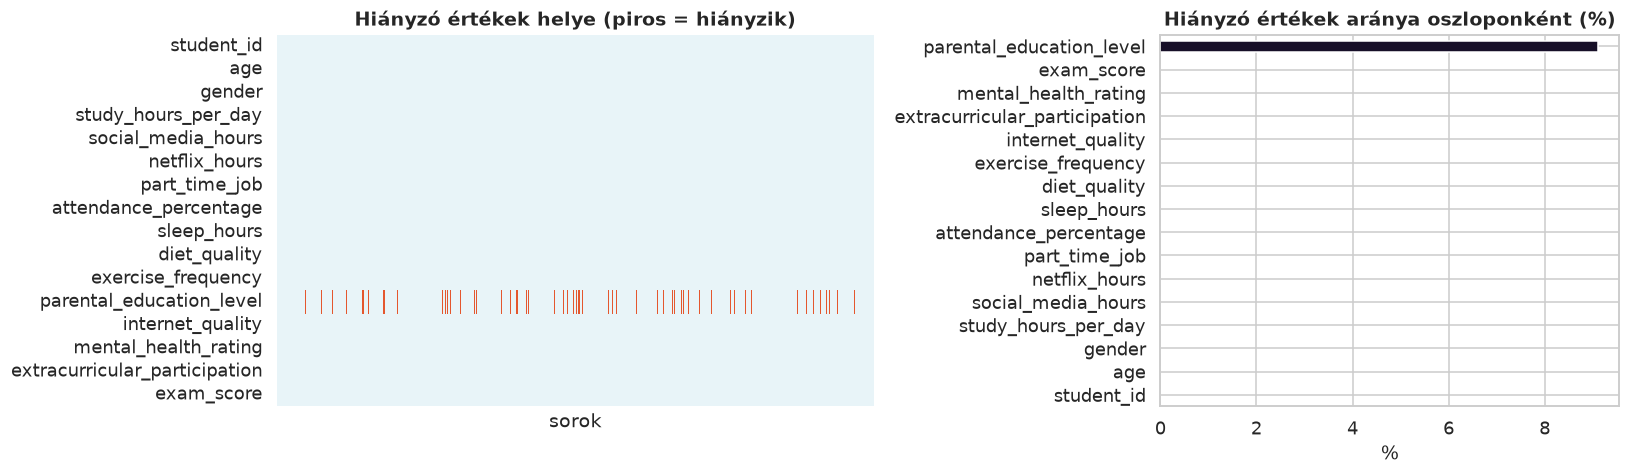

In [6]:
hianyzo = df_nyers.isna().sum()
hianyzo_arany = (hianyzo / len(df_nyers) * 100).round(2)
display(pd.DataFrame({"hiányzó db": hianyzo, "hiányzó %": hianyzo_arany}).query("`hiányzó db` > 0"))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(df_nyers.isna().T, cbar=False, cmap=["#e8f4f8", "#e4572e"], ax=axes[0])
axes[0].set_title("Hiányzó értékek helye (piros = hiányzik)")
axes[0].set_xticks([])
axes[0].set_xlabel("sorok")

hianyzo_arany.sort_values().plot.barh(ax=axes[1], color=sns.color_palette("rocket_r", len(hianyzo_arany)))
axes[1].set_title("Hiányzó értékek aránya oszloponként (%)")
axes[1].set_xlabel("%")
plt.tight_layout(); ment("01_hianyzo_ertekek"); plt.show()

**Megfigyelés:** A hiányzó értékek gyakorlatilag csak a `parental_education_level` oszlopban vannak. Valószínűleg azok a diákok,
akik nem tudták vagy nem akarták megadni a szüleik végzettségét. Ezt a 4. fejezetben kezelem.

## 3. Eloszlások vizsgálata és értelmezése

Külön nézem a numerikus és a kategorikus változókat. A numerikusaknál hisztogramot (sűrűségbecsléssel) és dobozábrát,
a kategorikusaknál oszlopdiagramot használok.

In [7]:
cel = "exam_score"
num_oszlopok = [c for c in df_nyers.select_dtypes(include="number").columns if c != cel]
kat_oszlopok = [c for c in df_nyers.select_dtypes(exclude="number").columns if c != "student_id"]
print("Numerikus:", num_oszlopok)
print("Kategorikus:", kat_oszlopok)

Numerikus: ['age', 'study_hours_per_day', 'social_media_hours', 'netflix_hours', 'attendance_percentage', 'sleep_hours', 'exercise_frequency', 'mental_health_rating']
Kategorikus: ['gender', 'part_time_job', 'diet_quality', 'parental_education_level', 'internet_quality', 'extracurricular_participation']


### 3.1 A célváltozó: vizsgapontszám

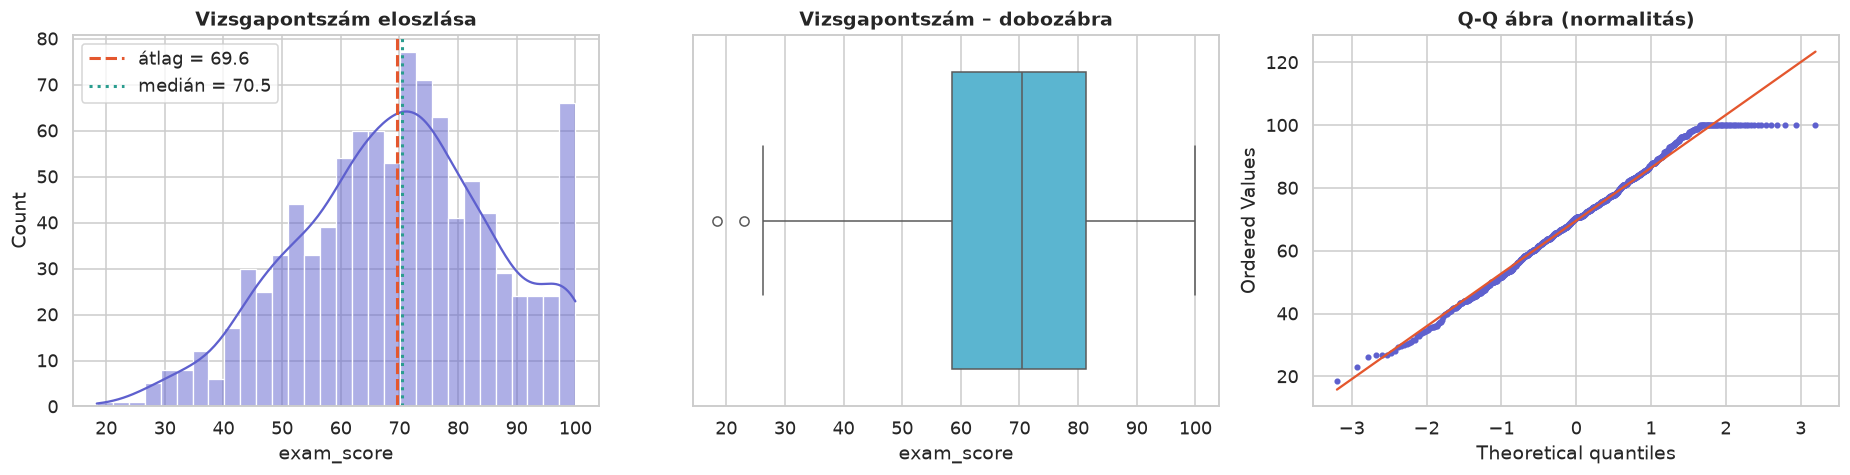

Ferdeség: -0.156,  csúcsosság: -0.420
Diákok aránya, akik elérték a 70 pontot: 51.1%


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.histplot(df_nyers[cel], bins=30, kde=True, color="#5e60ce", ax=axes[0])
axes[0].axvline(df_nyers[cel].mean(), color="#e4572e", ls="--", lw=2, label=f"átlag = {df_nyers[cel].mean():.1f}")
axes[0].axvline(df_nyers[cel].median(), color="#2a9d8f", ls=":", lw=2, label=f"medián = {df_nyers[cel].median():.1f}")
axes[0].legend(); axes[0].set_title("Vizsgapontszám eloszlása")

sns.boxplot(x=df_nyers[cel], color="#48bfe3", ax=axes[1])
axes[1].set_title("Vizsgapontszám – dobozábra")

stats.probplot(df_nyers[cel], dist="norm", plot=axes[2])
axes[2].get_lines()[0].set(color="#5e60ce", markersize=3)
axes[2].get_lines()[1].set(color="#e4572e")
axes[2].set_title("Q-Q ábra (normalitás)")
plt.tight_layout(); ment("02_celvaltozo"); plt.show()

print(f"Ferdeség: {df_nyers[cel].skew():.3f},  csúcsosság: {df_nyers[cel].kurt():.3f}")
print(f"Diákok aránya, akik elérték a 70 pontot: {(df_nyers[cel] >= 70).mean():.1%}")

**Értelmezés:** A pontszámok nagyjából normális eloszlásúak, az átlag kb. 69,6, a medián kb. 70,5 pont. A felső végen
látszik egy „torlódás” 100 pontnál (48 diák kapott pontosan 100-at), mert a pontszám felülről korlátos (plafonhatás).
Ez a Q-Q ábra jobb felső végén is látszik. A ferdeség kicsi (kb. −0,16), ezért nem kell transzformálni a célváltozót.
A diákok kb. fele éri el a 70 pontot, így az osztályozási feladatban kiegyensúlyozottak lesznek az osztályok.

### 3.2 Numerikus változók

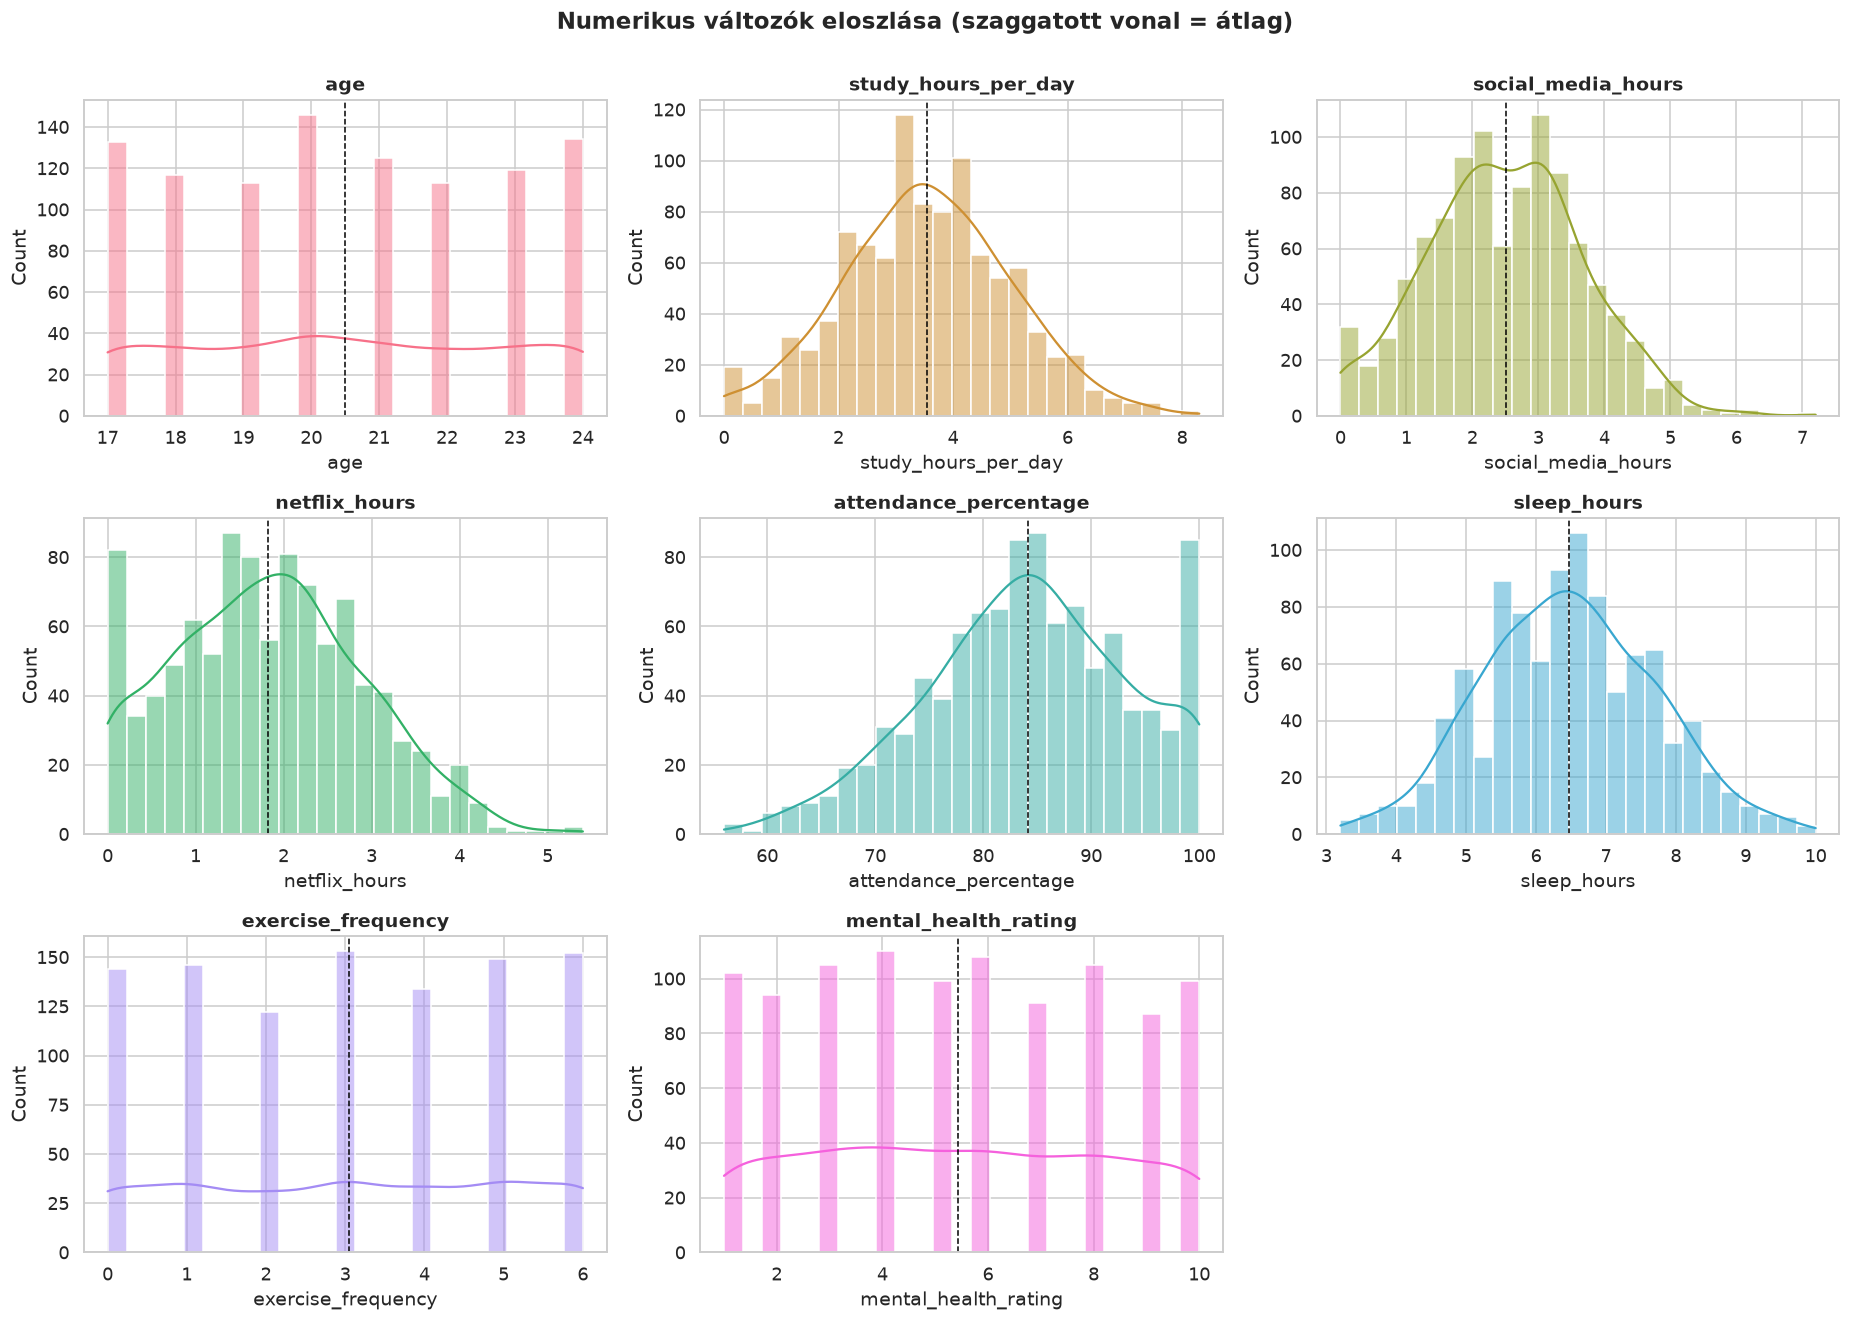

In [9]:
szinek = sns.color_palette("husl", len(num_oszlopok))
n = len(num_oszlopok)
fig, axes = plt.subplots(int(np.ceil(n / 3)), 3, figsize=(17, 4 * int(np.ceil(n / 3))))
for ax, col, szin in zip(axes.flat, num_oszlopok, szinek):
    sns.histplot(df_nyers[col], kde=True, color=szin, ax=ax, bins=25, edgecolor="white")
    ax.axvline(df_nyers[col].mean(), color="black", ls="--", lw=1)
    ax.set_title(col)
for ax in axes.flat[n:]:
    ax.set_visible(False)
plt.suptitle("Numerikus változók eloszlása (szaggatott vonal = átlag)", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout(); ment("03_numerikus_eloszlasok"); plt.show()

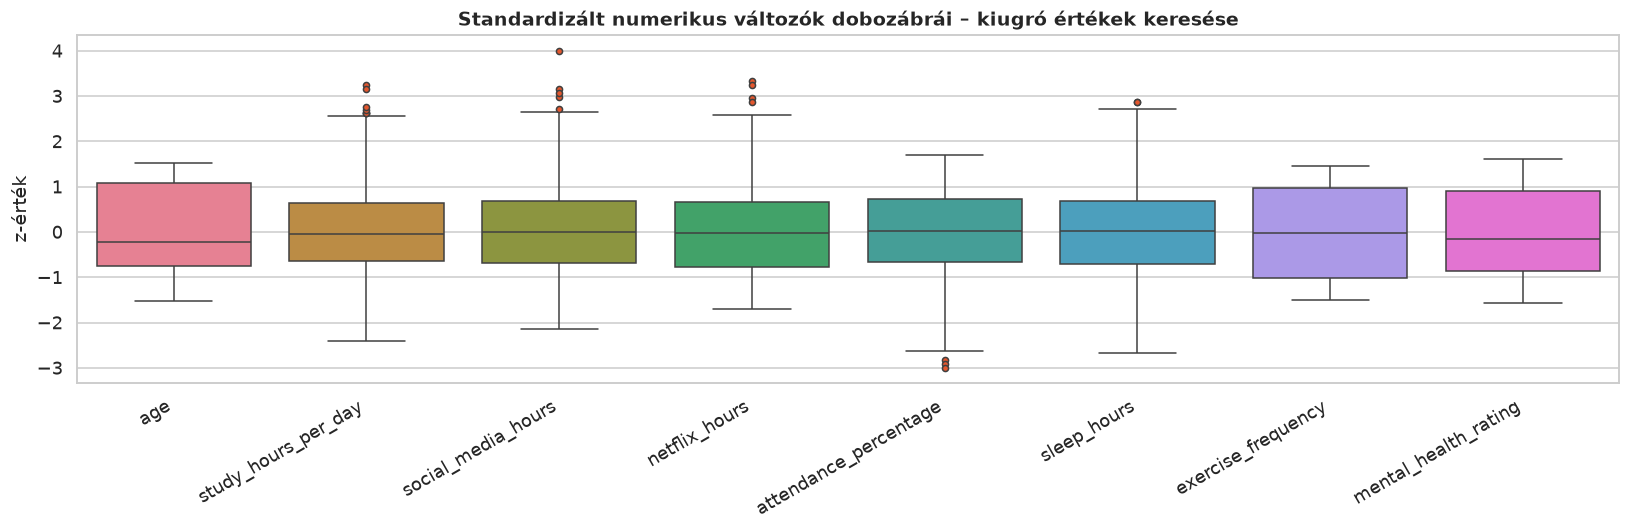

In [10]:
fig, ax = plt.subplots(figsize=(15, 5))
skalazott = (df_nyers[num_oszlopok] - df_nyers[num_oszlopok].mean()) / df_nyers[num_oszlopok].std()
sns.boxplot(data=skalazott, palette="husl", ax=ax, flierprops={"marker": "o", "markerfacecolor": "#e4572e", "markersize": 4})
ax.set_title("Standardizált numerikus változók dobozábrái – kiugró értékek keresése")
ax.set_ylabel("z-érték")
plt.xticks(rotation=30, ha="right")
plt.tight_layout(); ment("04_boxplotok"); plt.show()

**Értelmezés:**
- A `study_hours_per_day` nagyjából normális, átlagosan napi kb. 3–4 óra tanulás. Van néhány nagyon sokat (7–8 órát) tanuló diák.
- A `social_media_hours` és a `netflix_hours` enyhén jobbra ferde: a legtöbben mérsékelten használják, de van egy „sokat nézők” farok.
- A `sleep_hours` 6–7 óra körül mozog, ami kevesebb az ajánlott 7–9 óránál.
- Az `attendance_percentage` balra ferde, a legtöbben sokat járnak órára.
- Az `age` (17–24), az `exercise_frequency` (0–6 nap) és a `mental_health_rating` (1–10) diszkrét, közel egyenletes eloszlású változók.
- A dobozábrán látszó kiugró pontok **nem tűnnek hibának** (pl. napi 7 óra Netflix szélsőséges, de lehetséges), ezért nem dobom el őket automatikusan. A 4. fejezetben megnézem, hogy van-e logikailag lehetetlen érték.

### 3.3 Kategorikus változók

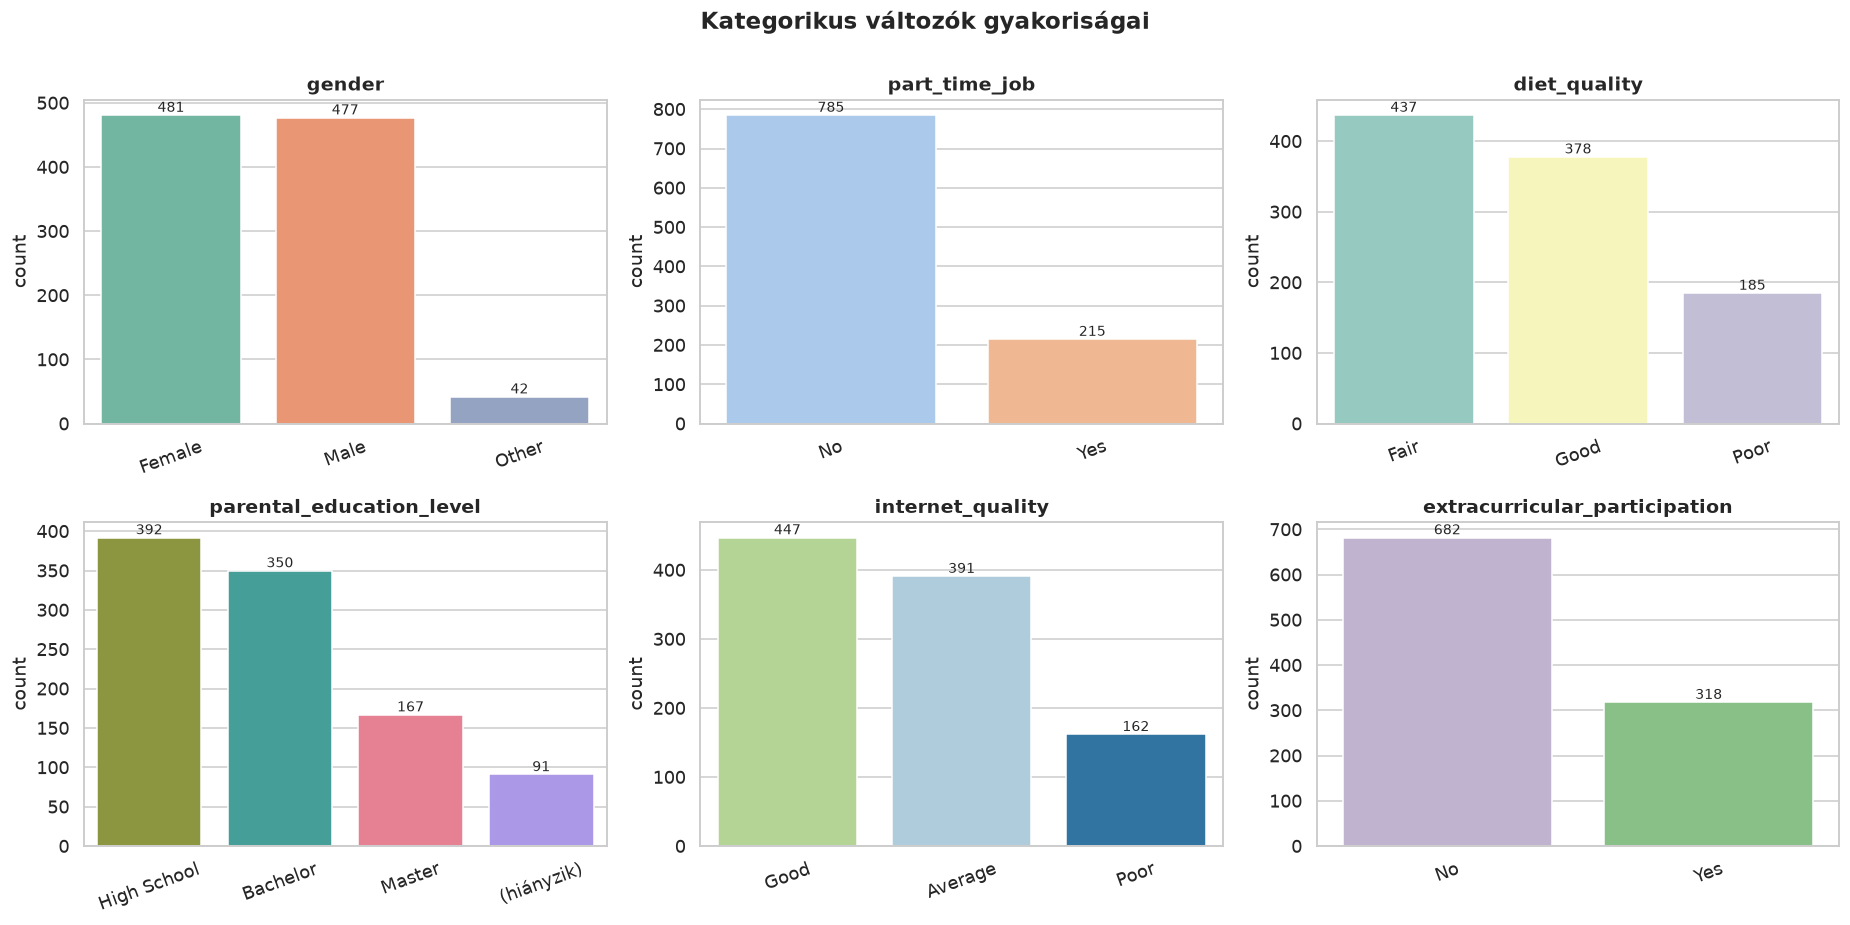

In [11]:
n = len(kat_oszlopok)
fig, axes = plt.subplots(int(np.ceil(n / 3)), 3, figsize=(17, 4.2 * int(np.ceil(n / 3))))
paletta_lista = ["Set2", "pastel", "Set3", "husl", "Paired", "Accent", "spring"]
for ax, col, pal in zip(axes.flat, kat_oszlopok, paletta_lista):
    rend = df_nyers[col].value_counts(dropna=False).index
    adat = df_nyers[col].fillna("(hiányzik)")
    rend = [r if pd.notna(r) else "(hiányzik)" for r in rend]
    sns.countplot(x=adat, order=rend, hue=adat, palette=pal, legend=False, ax=ax)
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(col); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
for ax in axes.flat[n:]:
    ax.set_visible(False)
plt.suptitle("Kategorikus változók gyakoriságai", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout(); ment("05_kategorikus_eloszlasok"); plt.show()

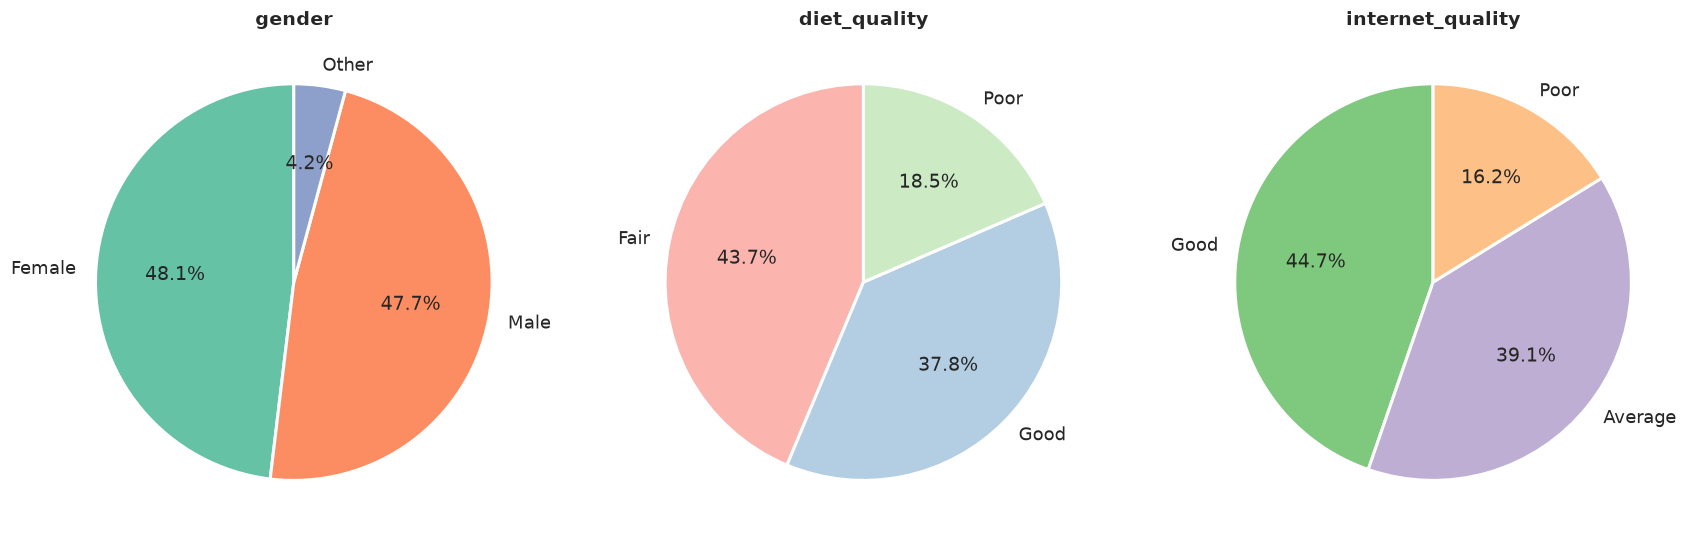

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col, pal in zip(axes, ["gender", "diet_quality", "internet_quality"], ["Set2", "Pastel1", "Accent"]):
    ertekek = df_nyers[col].value_counts()
    ax.pie(ertekek, labels=ertekek.index, autopct="%1.1f%%", startangle=90,
           colors=sns.color_palette(pal, len(ertekek)), wedgeprops={"edgecolor": "white", "linewidth": 2})
    ax.set_title(col)
plt.tight_layout(); ment("06_kordiagramok"); plt.show()

**Értelmezés:** A nemek aránya kiegyensúlyozott (az „Other” kategória kicsi). A diákok többsége nem dolgozik
és nem vesz részt tanórán kívüli tevékenységben. Az étkezés minősége főleg „Fair”. A kategóriák között nincs
olyan, ami csak néhány elemből állna (az „Other” nemet leszámítva), így az elemzésben mindegyiket meg tudom tartani.

## 4. Adatszűrés, adattisztítás

Lépések:
1. duplikált sorok és azonosítók keresése,
2. logikailag lehetetlen értékek szűrése (pl. negatív óraszám, 100% feletti jelenlét, 24 óránál több napi tevékenység),
3. hiányzó értékek kezelése,
4. a felesleges oszlop (`student_id`) eldobása.

In [13]:
df = df_nyers.copy()
print("Duplikált sorok:", df.duplicated().sum())
print("Duplikált student_id:", df["student_id"].duplicated().sum())

szabalyok = {
    "age >= 15 és <= 100": df["age"].between(15, 100),
    "órák >= 0": (df[["study_hours_per_day", "social_media_hours", "netflix_hours", "sleep_hours"]] >= 0).all(axis=1),
    "napi összes tevékenység <= 24 óra": (df[["study_hours_per_day", "social_media_hours", "netflix_hours", "sleep_hours"]].sum(axis=1) <= 24),
    "jelenlét 0–100%": df["attendance_percentage"].between(0, 100),
    "sport 0–7 nap": df["exercise_frequency"].between(0, 7),
    "mentális értékelés 1–10": df["mental_health_rating"].between(1, 10),
    "pontszám 0–100": df["exam_score"].between(0, 100),
}
ellenorzes = pd.DataFrame({"szabály": szabalyok.keys(), "megsértő sorok": [(~m).sum() for m in szabalyok.values()]})
display(ellenorzes)

ervenyes = np.logical_and.reduce(list(szabalyok.values()))
df = df[ervenyes].drop_duplicates()
print("Sorok szűrés után:", len(df), f"(eldobva: {len(df_nyers) - len(df)})")

Duplikált sorok: 0
Duplikált student_id: 0


,szabály,megsértő sorok
0,age >= 15 és <= 100,0
1,órák >= 0,0
2,napi összes tevékenység <= 24 óra,0
3,jelenlét 0–100%,0
4,sport 0–7 nap,0
5,mentális értékelés 1–10,0
6,pontszám 0–100,0


Sorok szűrés után: 1000 (eldobva: 0)


### Hiányzó szülői végzettség

A `parental_education_level` értéke a sorok kb. 9%-ában hiányzik. Lehetőségeim:
- **sorok törlése:** kb. 9%-nyi adatot veszítenék,
- **módusz imputálás:** torzítaná az eloszlást a leggyakoribb kategória felé,
- **külön „Unknown” kategória:** megőrzi az információt, hogy nem adta meg.

Előbb megnézem, hogy különbözik-e a hiányzó csoport pontszáma a többiekétől.

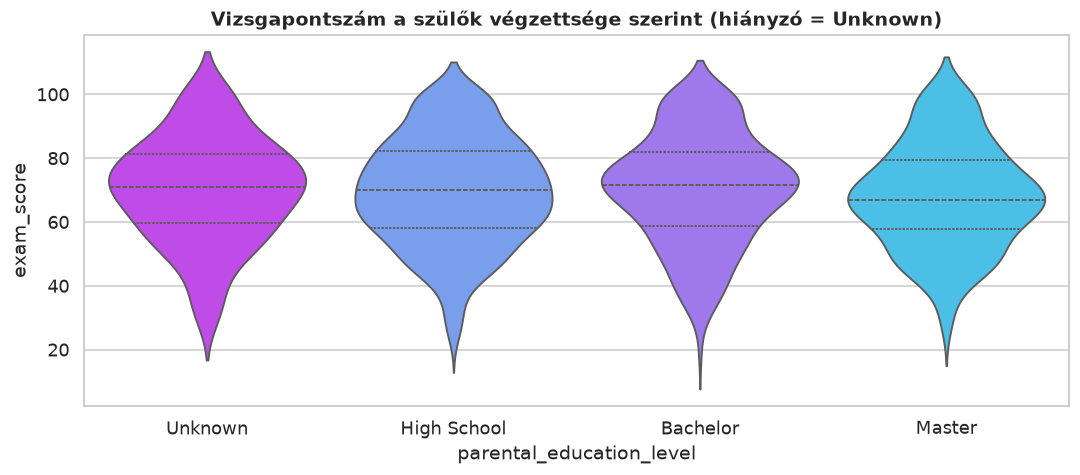

,count,mean,std
parental_education_level,,,
Bachelor,350,70.27,17.29
High School,392,69.55,16.83
Master,167,68.09,16.40
Unknown,91,70.03,16.56


In [14]:
df["parental_education_level"] = df["parental_education_level"].fillna("Unknown")

fig, ax = plt.subplots(figsize=(10, 4.5))
rend = ["Unknown", "High School", "Bachelor", "Master"]
rend = [r for r in rend if r in df["parental_education_level"].unique()]
sns.violinplot(data=df, x="parental_education_level", y=cel, order=rend, hue="parental_education_level",
               palette="cool", inner="quartile", legend=False, ax=ax)
ax.set_title("Vizsgapontszám a szülők végzettsége szerint (hiányzó = Unknown)")
plt.tight_layout(); ment("07_szuloi_vegzettseg"); plt.show()
display(df.groupby("parental_education_level")[cel].agg(["count", "mean", "std"]).round(2))

**Döntés:** A hiányzó csoport („Unknown”) pontszám-eloszlása nem tér el lényegesen a többitől, ezért **külön kategóriaként megtartom**,
így nem kell sorokat törölni.

Végül eldobom a `student_id` oszlopot, mert csak azonosító, nincs benne előrejelző információ.

In [15]:
df = df.drop(columns="student_id").reset_index(drop=True)
print(df.shape)
df.head()

(1000, 15)


,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


## 5. Változók közötti kapcsolatok
### 5.1 Korrelációs mátrix

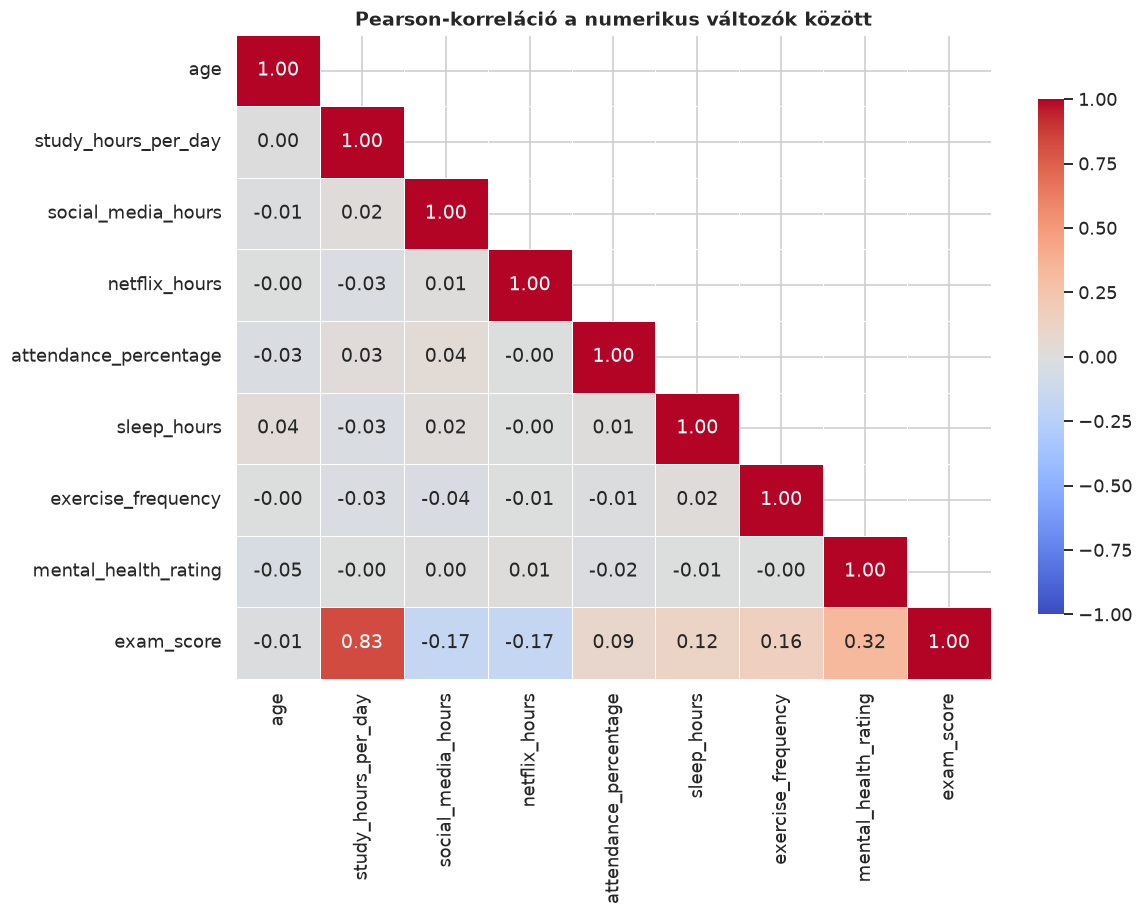

In [16]:
korr = df.select_dtypes(include="number").corr()
maszk = np.triu(np.ones_like(korr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 8.5))
sns.heatmap(korr, mask=maszk, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Pearson-korreláció a numerikus változók között")
plt.tight_layout(); ment("08_korrelacio"); plt.show()

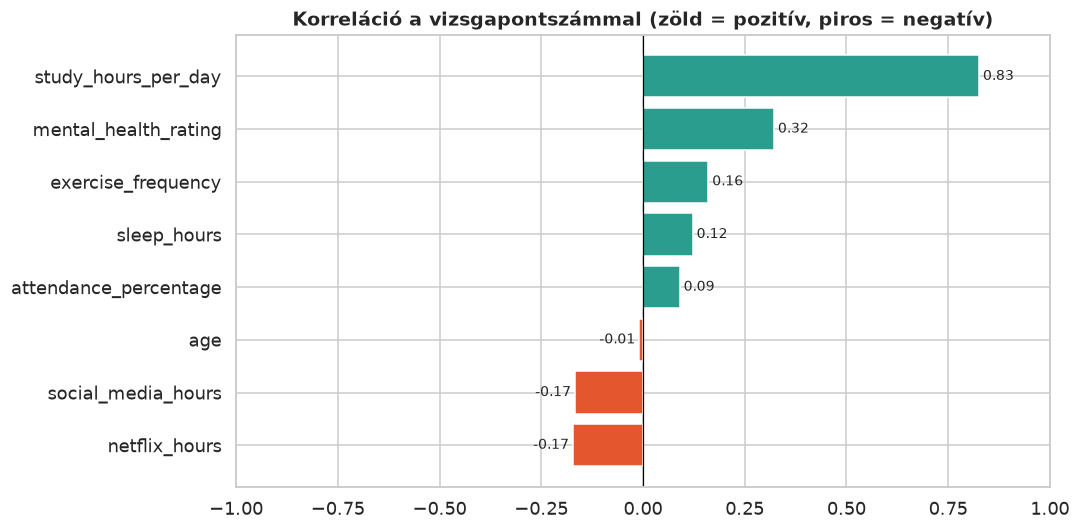

In [17]:
cel_korr = korr[cel].drop(cel).sort_values()
fig, ax = plt.subplots(figsize=(10, 5))
szinek = ["#e4572e" if v < 0 else "#2a9d8f" for v in cel_korr]
ax.barh(cel_korr.index, cel_korr.values, color=szinek)
for i, v in enumerate(cel_korr.values):
    ax.text(v + (0.01 if v >= 0 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", lw=.8)
ax.set_title("Korreláció a vizsgapontszámmal (zöld = pozitív, piros = negatív)")
ax.set_xlim(-1, 1)
plt.tight_layout(); ment("09_cel_korrelacio"); plt.show()

**Értelmezés:** Messze a **napi tanulási idő** áll a legerősebb kapcsolatban a pontszámmal (r ≈ 0,83). Utána a **mentális állapot**
következik (r ≈ 0,32). Gyenge kapcsolatban áll a pontszámmal a **Netflix** és a **közösségi média** (negatívan, kb. −0,17),
a **sport** (0,16), az **alvás** (0,12) és az **óralátogatás** (0,09).
Az életkor gyakorlatilag nem számít. A magyarázó változók egymással csak gyengén korrelálnak, tehát nincs komoly
multikollinearitás, ami a lineáris modelleknél jó hír.

### 5.2 A legfontosabb numerikus változók és a pontszám

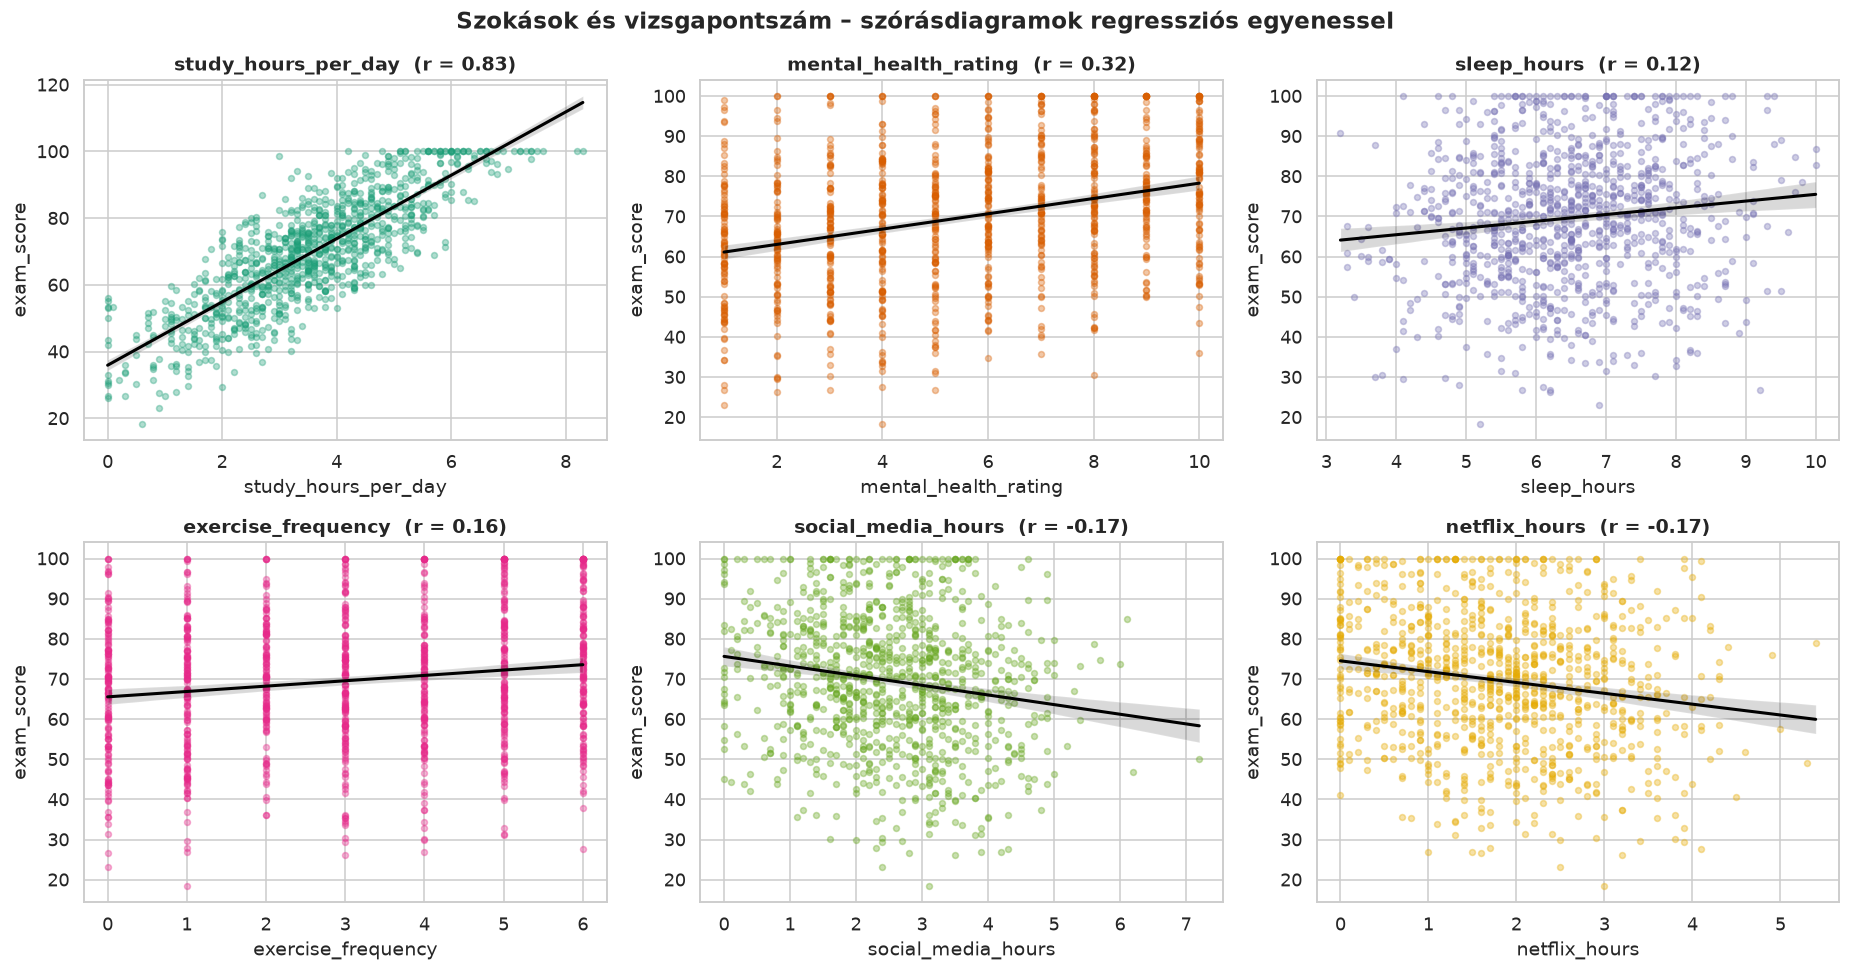

In [18]:
fontos = ["study_hours_per_day", "mental_health_rating", "sleep_hours", "exercise_frequency",
          "social_media_hours", "netflix_hours"]
szinek = sns.color_palette("Dark2", len(fontos))
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, col, szin in zip(axes.flat, fontos, szinek):
    sns.regplot(data=df, x=col, y=cel, ax=ax, color=szin, scatter_kws={"alpha": .35, "s": 15},
                line_kws={"color": "black", "lw": 2})
    r = df[col].corr(df[cel])
    ax.set_title(f"{col}  (r = {r:.2f})")
plt.suptitle("Szokások és vizsgapontszám – szórásdiagramok regressziós egyenessel", fontsize=15, fontweight="bold")
plt.tight_layout(); ment("10_szorasdiagramok"); plt.show()

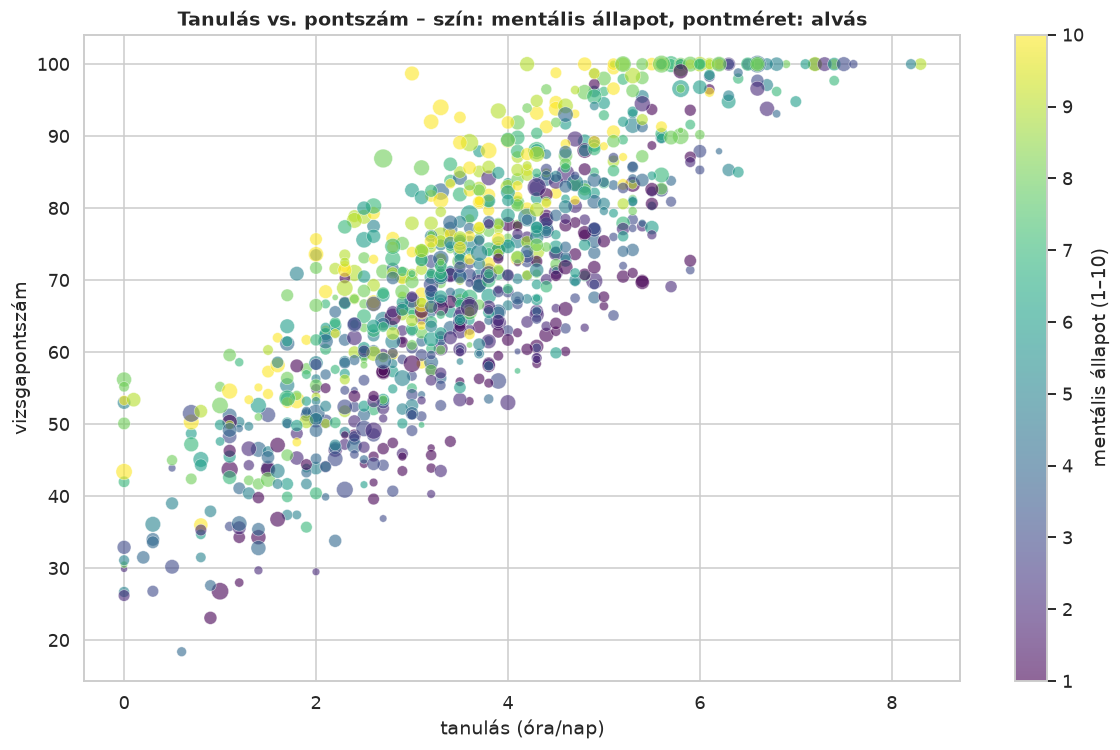

In [19]:
fig, ax = plt.subplots(figsize=(11, 7))
sc = ax.scatter(df["study_hours_per_day"], df[cel], c=df["mental_health_rating"], cmap="viridis",
                s=df["sleep_hours"] ** 2 * 1.5, alpha=.6, edgecolor="white", linewidth=.4)
plt.colorbar(sc, label="mentális állapot (1–10)")
ax.set_xlabel("tanulás (óra/nap)"); ax.set_ylabel("vizsgapontszám")
ax.set_title("Tanulás vs. pontszám – szín: mentális állapot, pontméret: alvás")
plt.tight_layout(); ment("11_buborek"); plt.show()

**Értelmezés:** A buborékdiagramon jól látszik, hogy azonos tanulási idő mellett a jobb mentális állapotú (sárgás) diákok
általában feljebb vannak. A tanulás hatása tehát nem önmagában érvényesül, a jóllét is számít.

### 5.3 Kategorikus változók és a pontszám

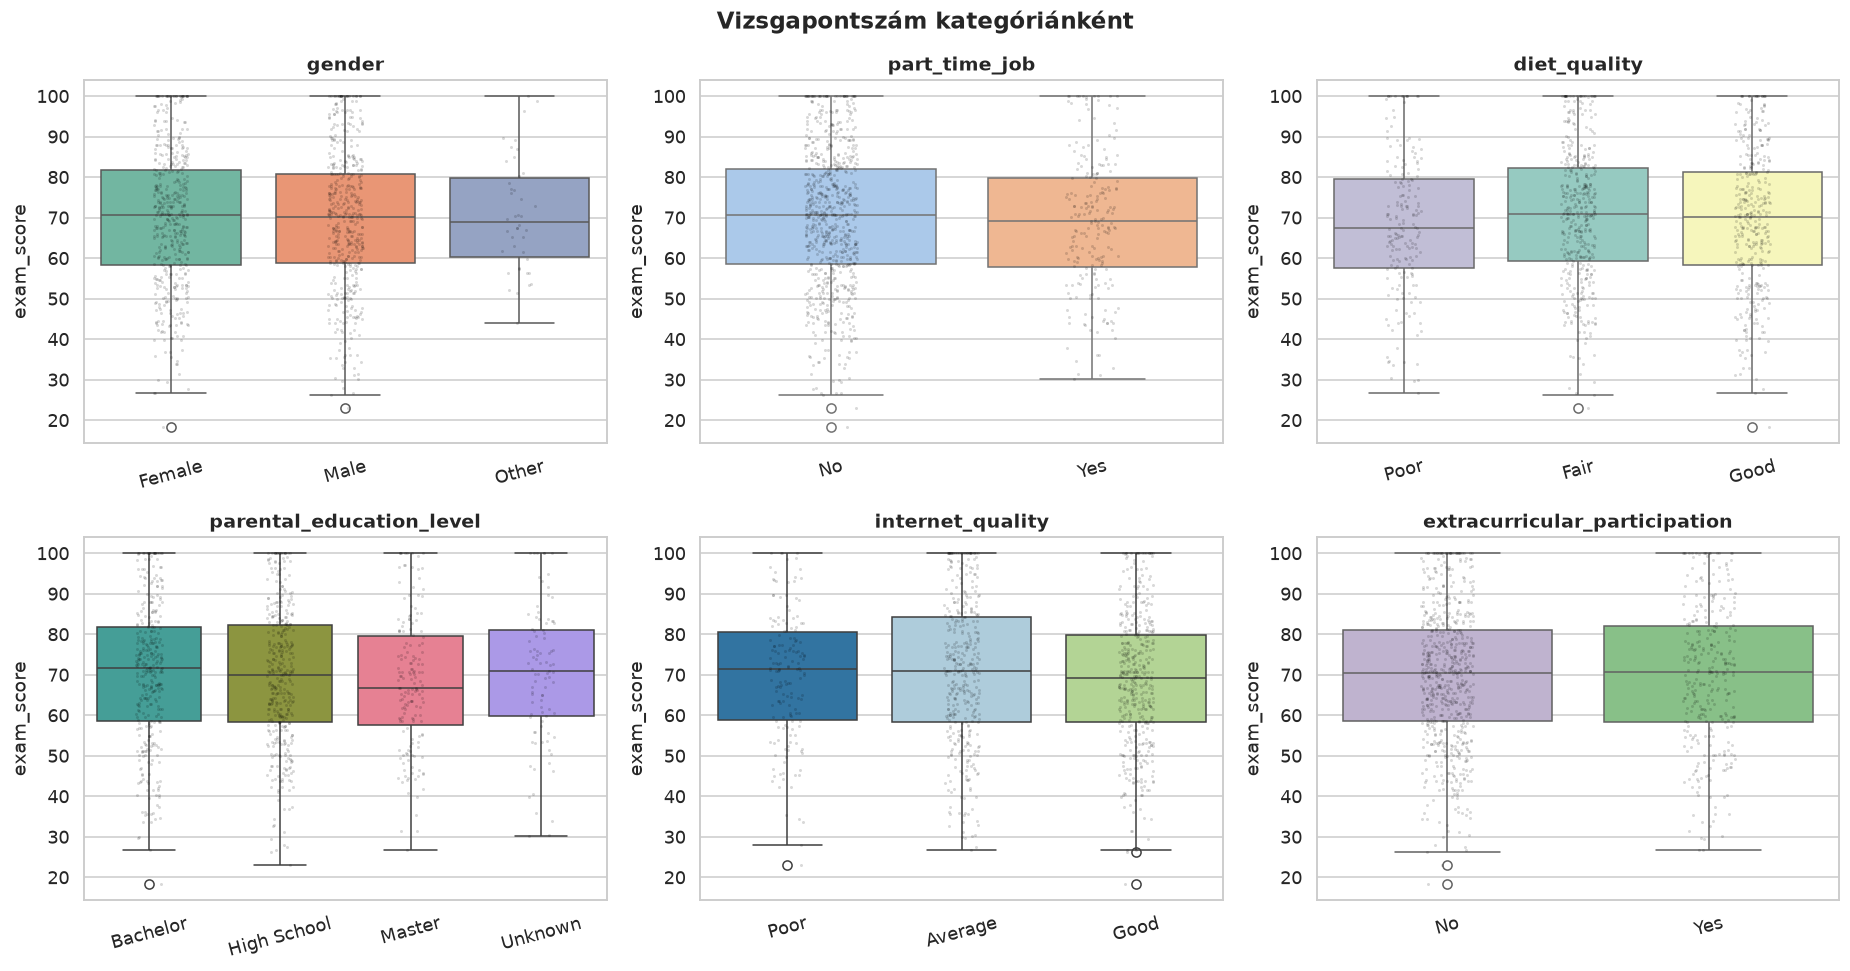

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
kat_rend = {"diet_quality": ["Poor", "Fair", "Good"], "internet_quality": ["Poor", "Average", "Good"]}
for ax, col, pal in zip(axes.flat, kat_oszlopok, ["Set2", "pastel", "Set3", "husl", "Paired", "Accent"]):
    rend = kat_rend.get(col, sorted(df[col].unique()))
    sns.boxplot(data=df, x=col, y=cel, order=rend, hue=col, palette=pal, legend=False, ax=ax)
    sns.stripplot(data=df, x=col, y=cel, order=rend, color="black", alpha=.15, size=2, ax=ax)
    ax.set_title(col); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=15)
for ax in axes.flat[len(kat_oszlopok):]:
    ax.set_visible(False)
plt.suptitle("Vizsgapontszám kategóriánként", fontsize=15, fontweight="bold")
plt.tight_layout(); ment("12_kategoriak_vs_pontszam"); plt.show()

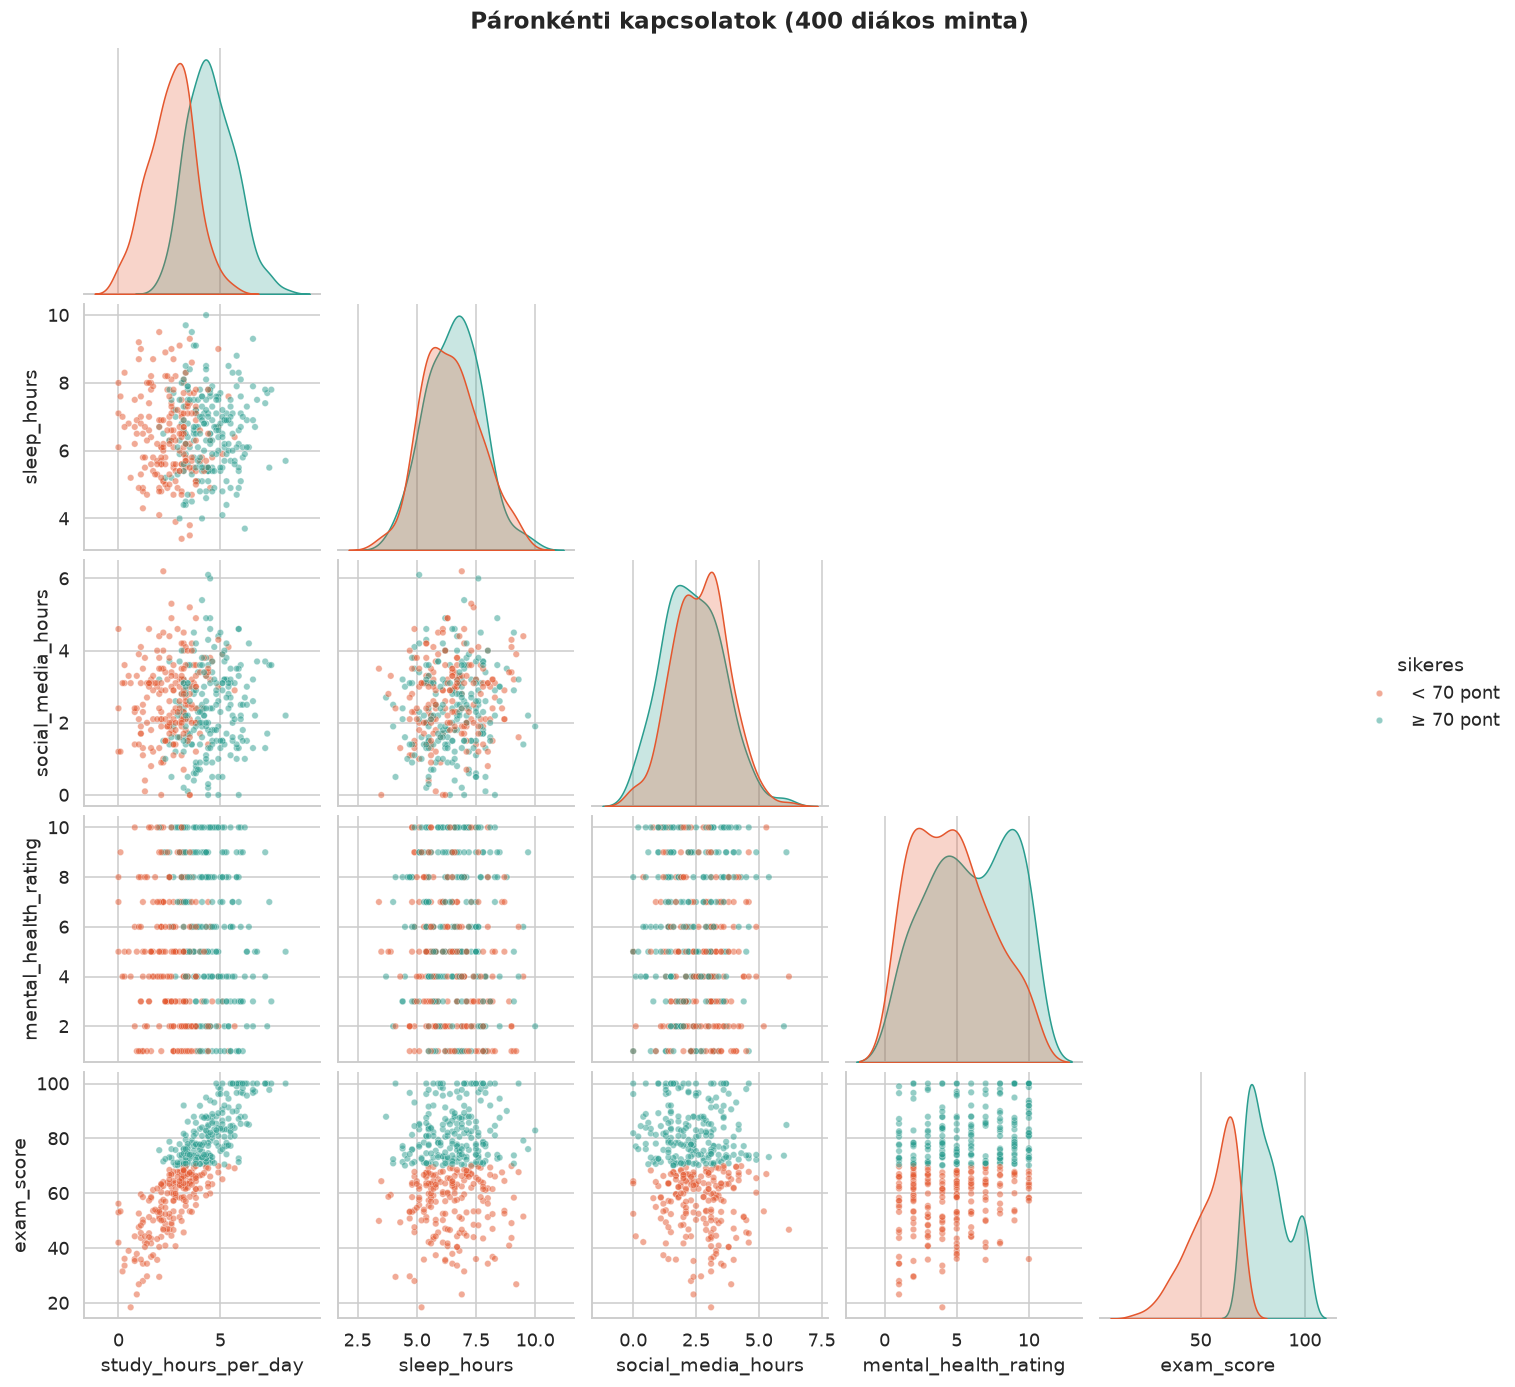

In [21]:
mintavetel = df.sample(min(400, len(df)), random_state=RANDOM_STATE).copy()
mintavetel["sikeres"] = np.where(mintavetel[cel] >= 70, "≥ 70 pont", "< 70 pont")
g = sns.pairplot(mintavetel, vars=["study_hours_per_day", "sleep_hours", "social_media_hours", "mental_health_rating", cel],
                 hue="sikeres", palette={"≥ 70 pont": "#2a9d8f", "< 70 pont": "#e4572e"},
                 plot_kws={"alpha": .5, "s": 18}, diag_kind="kde", corner=True)
g.figure.suptitle("Páronkénti kapcsolatok (400 diákos minta)", y=1.01, fontsize=15, fontweight="bold")
ment("13_pairplot"); plt.show()

**Értelmezés:** A kategorikus változók közül egyik sem mutat olyan erős különbséget, mint a numerikus szokások. A nem,
a részmunka vagy a szülők végzettsége szerint a dobozok nagyjából egy szinten vannak. A pairplot átlóján látszik, hogy
a „sikeres” és „sikertelen” csoport a tanulási időben válik szét a legjobban.

## 6. Hipotézisek és statisztikai tesztek

Az eddigiek alapján megfogalmazott hipotéziseim (szignifikanciaszint: α = 0,05):

| # | Hipotézis | Teszt |
|---|---|---|
| H1 | Aki többet tanul, jobb pontszámot ér el. | Pearson-korreláció |
| H2 | Aki többet alszik, jobb pontszámot ér el. | Pearson-korreláció |
| H3 | A több képernyőidő (közösségi média + Netflix) rosszabb pontszámmal jár. | Spearman-korreláció |
| H4 | A fiúk és a lányok pontszáma között nincs különbség. | Welch-féle t-próba |
| H5 | A részmunkaidős munka rontja a pontszámot. | Mann–Whitney U-próba |
| H6 | Az étkezés minősége szerint különbözik a pontszám. | egyutas ANOVA + Kruskal–Wallis |
| H7 | A jobb mentális állapot jobb pontszámmal jár. | Spearman-korreláció |

In [22]:
eredmenyek = []
def rogzit(h, teszt, stat, p, megjegyzes=""):
    eredmenyek.append({"hipotézis": h, "teszt": teszt, "statisztika": round(stat, 3), "p-érték": p,
                       "szignifikáns (p<0,05)": "igen" if p < 0.05 else "nem", "megjegyzés": megjegyzes})

r, p = stats.pearsonr(df["study_hours_per_day"], df[cel]);  rogzit("H1 tanulás", "Pearson r", r, p)
r, p = stats.pearsonr(df["sleep_hours"], df[cel]);          rogzit("H2 alvás", "Pearson r", r, p)
kepernyo = df["social_media_hours"] + df["netflix_hours"]
r, p = stats.spearmanr(kepernyo, df[cel]);                  rogzit("H3 képernyőidő", "Spearman ρ", r, p)

fiu, lany = df.loc[df.gender == "Male", cel], df.loc[df.gender == "Female", cel]
t, p = stats.ttest_ind(fiu, lany, equal_var=False)
rogzit("H4 nem (M vs F)", "Welch t", t, p, f"átlag: M={fiu.mean():.1f}, F={lany.mean():.1f}")

dolg, nem_dolg = df.loc[df.part_time_job == "Yes", cel], df.loc[df.part_time_job == "No", cel]
u, p = stats.mannwhitneyu(dolg, nem_dolg, alternative="less")
rogzit("H5 részmunka", "Mann–Whitney U (egyoldali)", u, p, f"medián: dolgozik={dolg.median():.1f}, nem={nem_dolg.median():.1f}")

csoportok = [g[cel].values for _, g in df.groupby("diet_quality")]
f, p = stats.f_oneway(*csoportok);   rogzit("H6 étkezés", "ANOVA F", f, p)
h, p = stats.kruskal(*csoportok);    rogzit("H6 étkezés", "Kruskal–Wallis H", h, p)

r, p = stats.spearmanr(df["mental_health_rating"], df[cel]); rogzit("H7 mentális állapot", "Spearman ρ", r, p)

hip_df = pd.DataFrame(eredmenyek)
def szinez(v):
    return "background-color: #b7e4c7" if v == "igen" else "background-color: #ffccd5"
hip_df.style.map(szinez, subset=["szignifikáns (p<0,05)"]).format({"p-érték": "{:.2e}"})

,hipotézis,teszt,statisztika,p-érték,"szignifikáns (p<0,05)",megjegyzés
0,H1 tanulás,Pearson r,0.825000,4.60e-250,igen,
1,H2 alvás,Pearson r,0.122000,1.15e-04,igen,
2,H3 képernyőidő,Spearman ρ,-0.228000,2.89e-13,igen,
3,H4 nem (M vs F),Welch t,-0.339000,7.35e-01,nem,"átlag: M=69.4, F=69.7"
4,H5 részmunka,Mann–Whitney U (egyoldali),80788.500000,1.69e-01,nem,"medián: dolgozik=69.2, nem=70.6"
5,H6 étkezés,ANOVA F,1.266000,2.82e-01,nem,
6,H6 étkezés,Kruskal–Wallis H,2.460000,2.92e-01,nem,
7,H7 mentális állapot,Spearman ρ,0.323000,9.00e-26,igen,


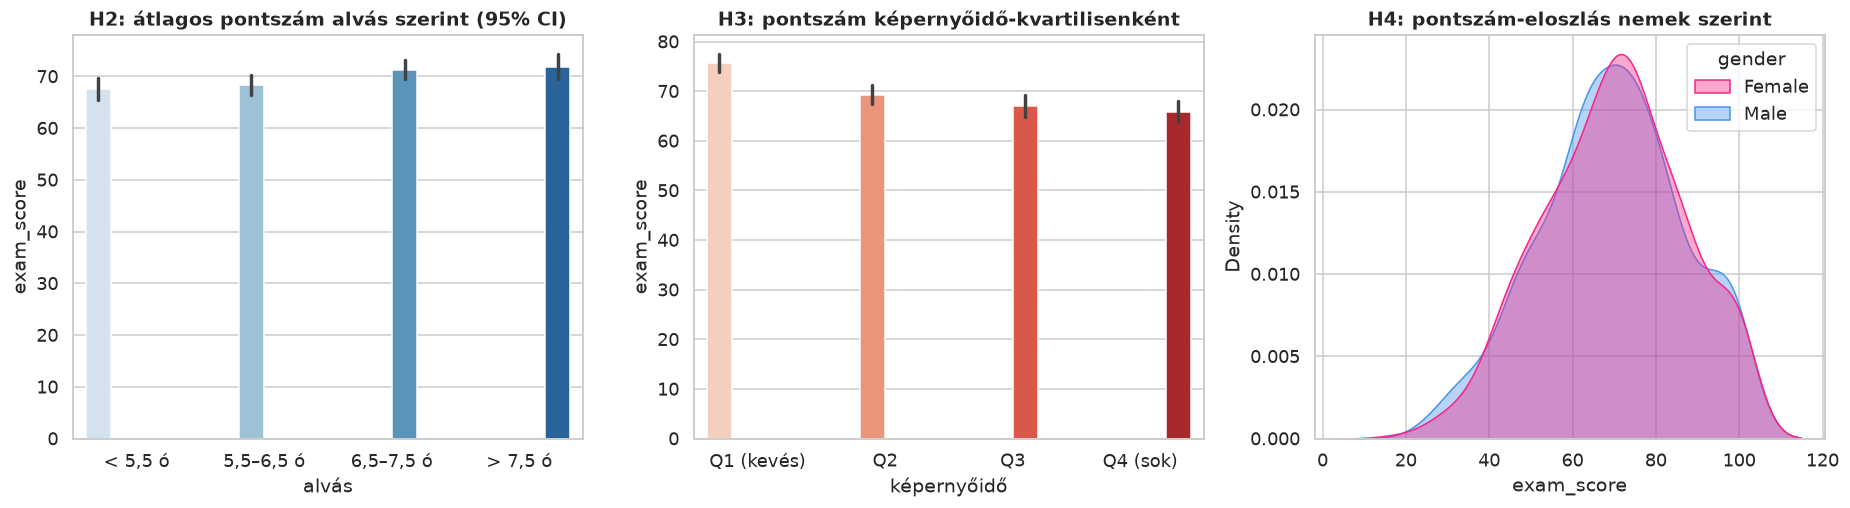

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

df["_alvas_kat"] = pd.cut(df["sleep_hours"], bins=[0, 5.5, 6.5, 7.5, 24], labels=["< 5,5 ó", "5,5–6,5 ó", "6,5–7,5 ó", "> 7,5 ó"])
sns.barplot(data=df, x="_alvas_kat", y=cel, hue="_alvas_kat", palette="Blues", errorbar=("ci", 95), legend=False, ax=axes[0])
axes[0].set_title("H2: átlagos pontszám alvás szerint (95% CI)"); axes[0].set_xlabel("alvás")

df["_kepernyo_kat"] = pd.qcut(kepernyo, 4, labels=["Q1 (kevés)", "Q2", "Q3", "Q4 (sok)"])
sns.barplot(data=df, x="_kepernyo_kat", y=cel, hue="_kepernyo_kat", palette="Reds", errorbar=("ci", 95), legend=False, ax=axes[1])
axes[1].set_title("H3: pontszám képernyőidő-kvartilisenként"); axes[1].set_xlabel("képernyőidő")

sns.kdeplot(data=df[df.gender.isin(["Male", "Female"])], x=cel, hue="gender", fill=True, alpha=.4,
            palette={"Male": "#4895ef", "Female": "#f72585"}, common_norm=False, ax=axes[2])
axes[2].set_title("H4: pontszám-eloszlás nemek szerint")
plt.tight_layout(); ment("14_hipotezisek"); plt.show()
df = df.drop(columns=["_alvas_kat", "_kepernyo_kat"])

**Következtetések a hipotézisekről** (a táblázat alapján):
- **H1, H7:** erősen szignifikáns pozitív kapcsolat, a tanulás és a mentális állapot számít a legtöbbet.
- **H2, H3:** az alvás pozitív, a képernyőidő negatív irányban szignifikáns, de a hatásuk jóval gyengébb a tanulásénál.
- **H4:** a nemek között nincs szignifikáns különbség (p ≈ 0,73), tehát a „nincs különbség” állítást nem kell elvetnem.
- **H5:** a dolgozó diákok mediánja kicsit alacsonyabb (69,2 vs. 70,6), de a különbség **nem szignifikáns** (p ≈ 0,17), ezért a hipotézist nem tudom alátámasztani.
- **H6:** az étkezés minősége szerint sem az ANOVA, sem a Kruskal–Wallis-próba nem mutat szignifikáns különbséget (p ≈ 0,28), ezt a hipotézist is elvetem.
- Tanulság: amit „józan ésszel” fontosnak gondoltam volna (munka, étkezés), az ebben az adatban nem számít.

Fontos: ezek **korrelációk, nem ok-okozati kapcsolatok**. Lehet például, hogy a motiváltabb diák egyszerre tanul többet és alszik jobban.

## 7. Jellemzők kinyerése és előfeldolgozás

Új jellemzők, amelyeket az elemzés alapján érdemesnek gondolok:

| Új jellemző | Képlet | Indoklás |
|---|---|---|
| `screen_time` | közösségi média + Netflix | a két „figyelemelterelő” együtt |
| `study_screen_ratio` | tanulás / (képernyőidő + 1) | a tanulás és a szórakozás aránya |
| `productive_hours` | tanulás × jelenlét / 100 | „hatékony” tanulási idő |
| `wellbeing_index` | standardizált (alvás + sport + mentális állapot) átlaga | általános jóllét |
| `sleep_ok` | 1, ha 7–9 óra alvás | ajánlott alvásmennyiség |

Kódolás:
- **ordinális** változók (`diet_quality`, `internet_quality`, `parental_education_level`) → sorrendet megtartó számok,
- **nominális** változók (`gender`) → one-hot kódolás,
- **bináris** Yes/No → 0/1,
- numerikus változók → standardizálás (a lineáris modellekhez, a KNN-hez és az SVM-hez kell).

A standardizálást és a kódolást **Pipeline-ba** teszem, így csak a tanító adaton illesztődik, és nem szivárog át információ a tesztadatból (data leakage).

In [24]:
def jellemzok_kinyerese(d):
    d = d.copy()
    d["screen_time"] = d["social_media_hours"] + d["netflix_hours"]
    d["study_screen_ratio"] = d["study_hours_per_day"] / (d["screen_time"] + 1)
    d["productive_hours"] = d["study_hours_per_day"] * d["attendance_percentage"] / 100
    z = lambda s: (s - s.mean()) / s.std()
    d["wellbeing_index"] = (z(d["sleep_hours"]) + z(d["exercise_frequency"]) + z(d["mental_health_rating"])) / 3
    d["sleep_ok"] = d["sleep_hours"].between(7, 9).astype(int)
    for col in ["part_time_job", "extracurricular_participation"]:
        d[col] = (d[col] == "Yes").astype(int)
    return d

df_fe = jellemzok_kinyerese(df)
uj = ["screen_time", "study_screen_ratio", "productive_hours", "wellbeing_index", "sleep_ok"]
df_fe[uj + [cel]].head()

,screen_time,study_screen_ratio,productive_hours,wellbeing_index,sleep_ok,exam_score
0,2.3,0.000000,0.0000,1.202556,1,56.2
1,5.1,1.131148,6.7137,0.278424,0,100.0
2,4.4,0.259259,1.3272,-0.439749,1,34.3
3,4.9,0.169492,0.7100,0.380139,0,26.8
4,4.9,0.847458,4.5450,-0.953190,0,66.4


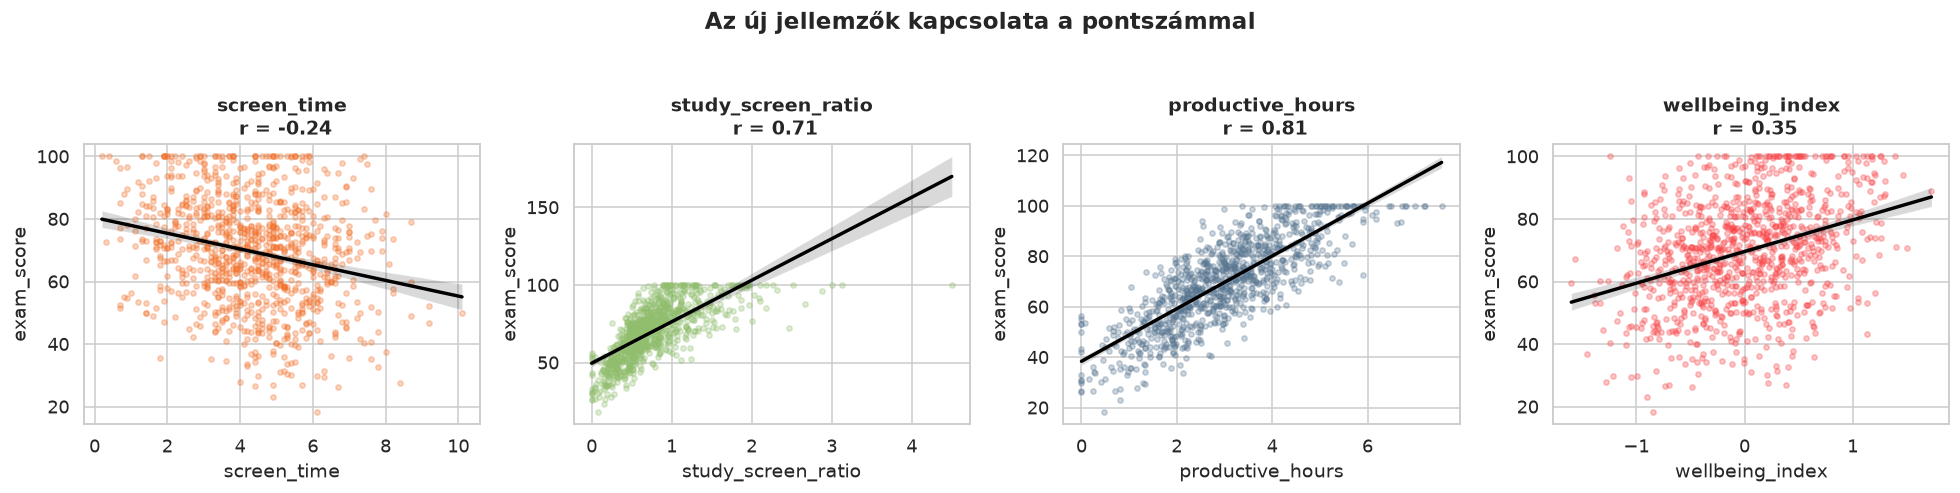

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
for ax, col, szin in zip(axes, uj[:4], ["#f3722c", "#90be6d", "#577590", "#f94144"]):
    sns.regplot(data=df_fe, x=col, y=cel, ax=ax, color=szin, scatter_kws={"alpha": .3, "s": 12}, line_kws={"color": "black"})
    ax.set_title(f"{col}\n r = {df_fe[col].corr(df_fe[cel]):.2f}")
plt.suptitle("Az új jellemzők kapcsolata a pontszámmal", fontsize=15, fontweight="bold", y=1.04)
plt.tight_layout(); ment("15_uj_jellemzok"); plt.show()

**Értelmezés:** A `productive_hours` és a `study_screen_ratio` hasonlóan erős, mint maga a tanulási idő. A `wellbeing_index`
egyetlen változóba sűríti az alvás, a sport és a mentális állapot együttes hatását. Hogy ezek valóban javítják-e a modelleket,
azt a 8. fejezetben külön összehasonlítom.

Tanító: (800, 19)  Teszt: (200, 19)


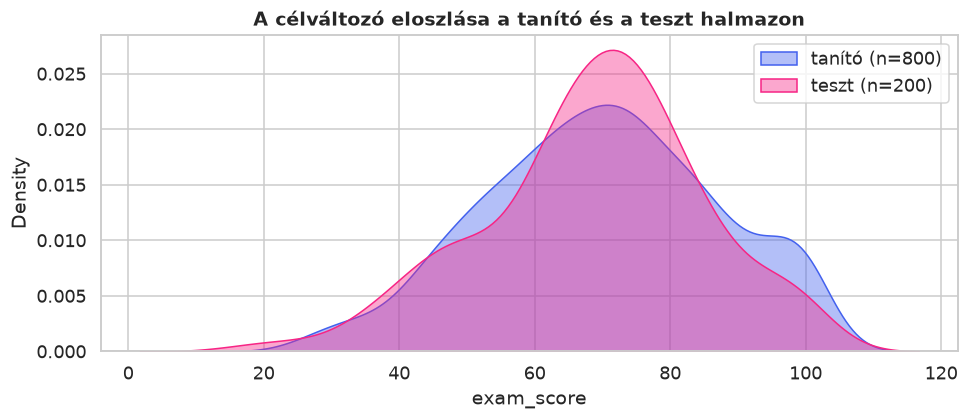

In [26]:
ORD_KAT = {
    "diet_quality": ["Poor", "Fair", "Good"],
    "internet_quality": ["Poor", "Average", "Good"],
    "parental_education_level": ["Unknown", "High School", "Bachelor", "Master"],
}
NOM_KAT = ["gender"]

X = df_fe.drop(columns=cel)
y = df_fe[cel]
num_cols = [c for c in X.columns if c not in list(ORD_KAT) + NOM_KAT]

def elofeldolgozo(numerikus):
    return ColumnTransformer([
        ("num", StandardScaler(), numerikus),
        ("ord", Pipeline([("enc", OrdinalEncoder(categories=list(ORD_KAT.values()), handle_unknown="use_encoded_value", unknown_value=-1)),
                          ("sc", StandardScaler())]), list(ORD_KAT)),
        ("nom", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), NOM_KAT),
    ])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Tanító:", X_train.shape, " Teszt:", X_test.shape)

fig, ax = plt.subplots(figsize=(9, 4))
sns.kdeplot(y_train, fill=True, color="#4361ee", alpha=.4, label=f"tanító (n={len(y_train)})", ax=ax)
sns.kdeplot(y_test, fill=True, color="#f72585", alpha=.4, label=f"teszt (n={len(y_test)})", ax=ax)
ax.set_title("A célváltozó eloszlása a tanító és a teszt halmazon"); ax.legend()
plt.tight_layout(); ment("16_train_test"); plt.show()

## 8. Regressziós modellek – a vizsgapontszám becslése

Vizsgált modellek, a legegyszerűbbtől a bonyolultabb felé:
1. **Baseline:** mindig az átlagot tippeli. Ehhez mérem a többit; ha egy modell ezt nem veri, akkor nem ér semmit.
2. **Lineáris regresszió:** jól értelmezhető, az EDA alapján a kapcsolatok nagyjából lineárisak.
3. **Ridge és Lasso:** regularizált lineáris modellek (a Lasso változókat is tud „kiválasztani”).
4. **KNN:** távolság alapú, nemparaméteres.
5. **Döntési fa:** nemlineáris, jól szemléltethető.
6. **Random Forest és Gradient Boosting:** együttes (ensemble) fa-modellek.
7. **SVR:** szupport vektor regresszió RBF kernellel.

Kiértékelés: **5-szörös keresztvalidáció** a tanító halmazon, majd a végső mérés a **félretett teszthalmazon**.
Metrikák: **R²** (megmagyarázott variancia), **MAE** (átlagos abszolút hiba pontban), **RMSE**.

In [27]:
reg_modellek = {
    "Baseline (átlag)": DummyRegressor(strategy="mean"),
    "Lineáris regresszió": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1),
    "KNN": KNeighborsRegressor(n_neighbors=10),
    "Döntési fa": DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
    "SVR": SVR(C=10, epsilon=0.5),
}
kf = KFold(5, shuffle=True, random_state=RANDOM_STATE)

reg_eredmeny, cv_r2_reszletes, reg_pipek = [], {}, {}
for nev, modell in reg_modellek.items():
    pipe = Pipeline([("pre", elofeldolgozo(num_cols)), ("model", modell)])
    cv = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2")
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    reg_pipek[nev] = pipe
    cv_r2_reszletes[nev] = cv
    reg_eredmeny.append({"modell": nev, "CV R² (átlag)": cv.mean(), "CV R² (szórás)": cv.std(),
                         "teszt R²": r2_score(y_test, pred), "teszt MAE": mean_absolute_error(y_test, pred),
                         "teszt RMSE": np.sqrt(mean_squared_error(y_test, pred))})

reg_df = pd.DataFrame(reg_eredmeny).set_index("modell").sort_values("teszt R²", ascending=False)
(reg_df.style.background_gradient(cmap="Greens", subset=["CV R² (átlag)", "teszt R²"])
       .background_gradient(cmap="Reds", subset=["teszt MAE", "teszt RMSE"]).format("{:.3f}"))

,CV R² (átlag),CV R² (szórás),teszt R²,teszt MAE,teszt RMSE
modell,,,,,
Lineáris regresszió,0.895,0.015,0.900,4.139,5.074
Ridge,0.895,0.016,0.899,4.136,5.079
Lasso,0.897,0.016,0.898,4.149,5.109
Random Forest,0.876,0.013,0.885,4.312,5.441
Gradient Boosting,0.880,0.012,0.878,4.419,5.591
SVR,0.858,0.011,0.867,4.875,5.837
Döntési fa,0.789,0.012,0.809,5.400,7.002
KNN,0.759,0.019,0.747,6.298,8.055
Baseline (átlag),-0.005,0.006,-0.005,12.380,16.053


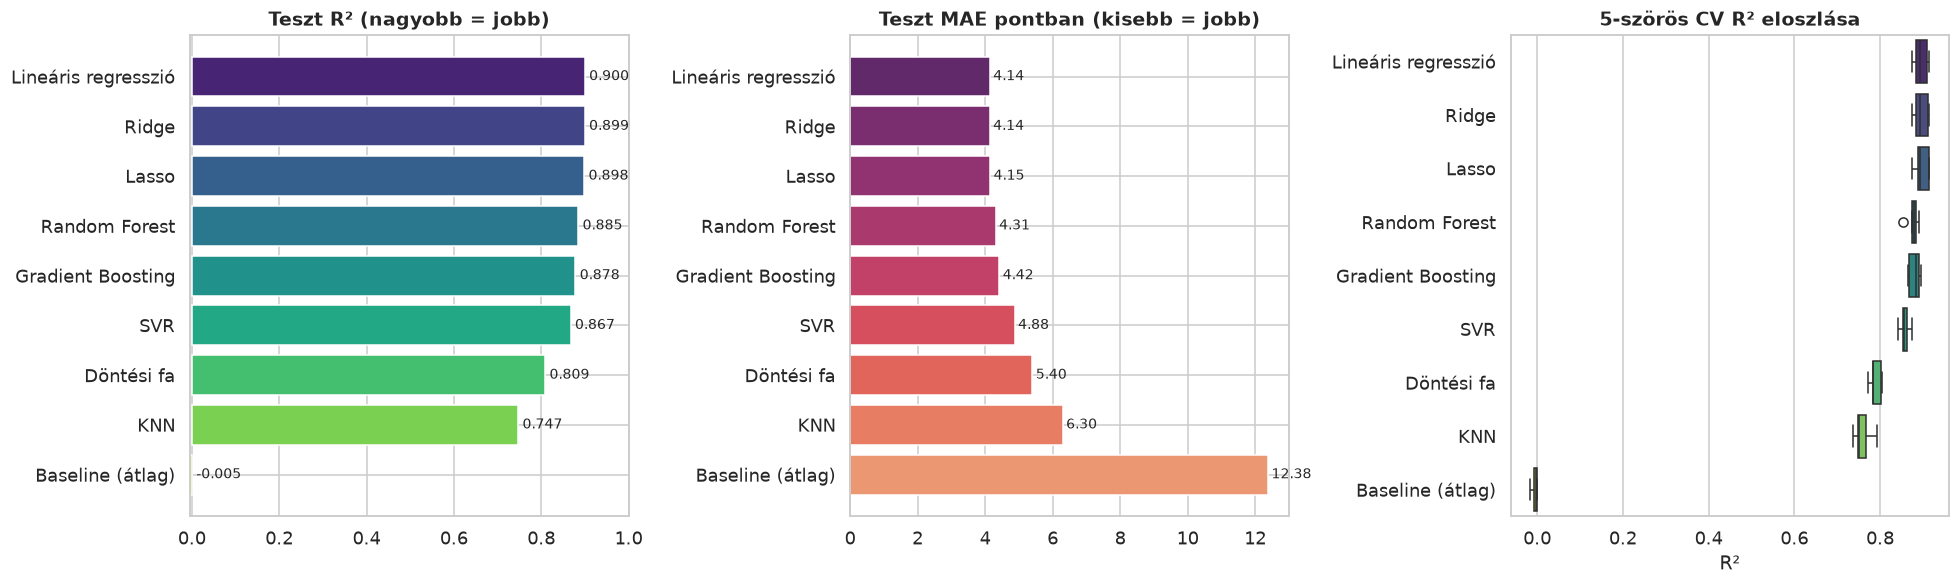

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
rend = reg_df.index
szinek = sns.color_palette("viridis", len(rend))

axes[0].barh(rend[::-1], reg_df["teszt R²"][::-1], color=szinek[::-1])
axes[0].set_title("Teszt R² (nagyobb = jobb)"); axes[0].set_xlim(min(0, reg_df["teszt R²"].min()), 1)
for i, v in enumerate(reg_df["teszt R²"][::-1]): axes[0].text(max(v, 0) + .01, i, f"{v:.3f}", va="center", fontsize=9)

axes[1].barh(rend[::-1], reg_df["teszt MAE"][::-1], color=sns.color_palette("flare", len(rend)))
axes[1].set_title("Teszt MAE pontban (kisebb = jobb)")
for i, v in enumerate(reg_df["teszt MAE"][::-1]): axes[1].text(v + .1, i, f"{v:.2f}", va="center", fontsize=9)

cv_long = pd.DataFrame(cv_r2_reszletes)[list(rend)].melt(var_name="modell", value_name="R²")
sns.boxplot(data=cv_long, y="modell", x="R²", hue="modell", palette="viridis", legend=False, ax=axes[2])
axes[2].set_title("5-szörös CV R² eloszlása"); axes[2].set_ylabel("")
plt.tight_layout(); ment("17_regresszio_osszehasonlitas"); plt.show()

**Értelmezés:** A baseline R² értéke kb. 0, ahogy várható. Minden valódi modell jóval jobb nála. A **lineáris modellek**
(lineáris regresszió, Ridge, Lasso) a legjobbak között vannak, ami megerősíti az EDA-ból levont következtetést, hogy a
kapcsolatok nagyrészt lineárisak. A bonyolultabb modellek (Random Forest, Gradient Boosting) nem hoznak érdemi javulást.
A döntési fa és a KNN gyengébb. A CV-szórás minden jó modellnél kicsi, tehát az eredmény stabil, nem a szerencsés felosztáson múlik.

### 8.1 Hiperparaméter-hangolás (Random Forest és Ridge)

Megnézem, hogy hangolással behozható-e a különbség.

RF legjobb paraméterek: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}  CV R² = 0.8766
Ridge legjobb alpha: 0.3162  CV R² = 0.8952


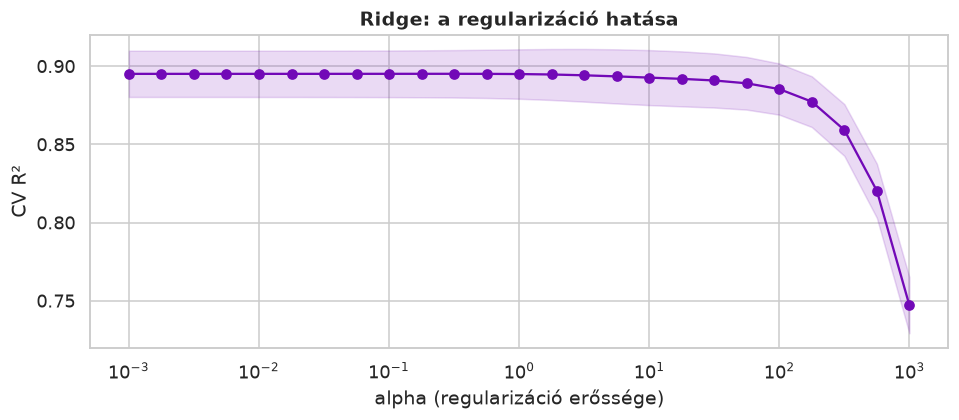

In [29]:
rf_grid = GridSearchCV(
    Pipeline([("pre", elofeldolgozo(num_cols)), ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
    {"model__n_estimators": [200, 400], "model__max_depth": [None, 8, 14], "model__min_samples_leaf": [1, 4]},
    cv=kf, scoring="r2", n_jobs=-1)
rf_grid.fit(X_train, y_train)

ridge_grid = GridSearchCV(
    Pipeline([("pre", elofeldolgozo(num_cols)), ("model", Ridge())]),
    {"model__alpha": np.logspace(-3, 3, 25)}, cv=kf, scoring="r2")
ridge_grid.fit(X_train, y_train)

print("RF legjobb paraméterek:", rf_grid.best_params_, f" CV R² = {rf_grid.best_score_:.4f}")
print("Ridge legjobb alpha:", round(ridge_grid.best_params_["model__alpha"], 4), f" CV R² = {ridge_grid.best_score_:.4f}")

alphak = ridge_grid.cv_results_["param_model__alpha"].data.astype(float)
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogx(alphak, ridge_grid.cv_results_["mean_test_score"], "o-", color="#7209b7")
ax.fill_between(alphak, ridge_grid.cv_results_["mean_test_score"] - ridge_grid.cv_results_["std_test_score"],
                ridge_grid.cv_results_["mean_test_score"] + ridge_grid.cv_results_["std_test_score"], color="#7209b7", alpha=.15)
ax.set_xlabel("alpha (regularizáció erőssége)"); ax.set_ylabel("CV R²")
ax.set_title("Ridge: a regularizáció hatása")
plt.tight_layout(); ment("18_ridge_alpha"); plt.show()

### 8.2 Megérnek-e valamit az új jellemzők?

Ugyanazt a modellt két változatban tanítom: csak az eredeti oszlopokkal, illetve az eredeti oszlopok mellett az új jellemzőkkel is.

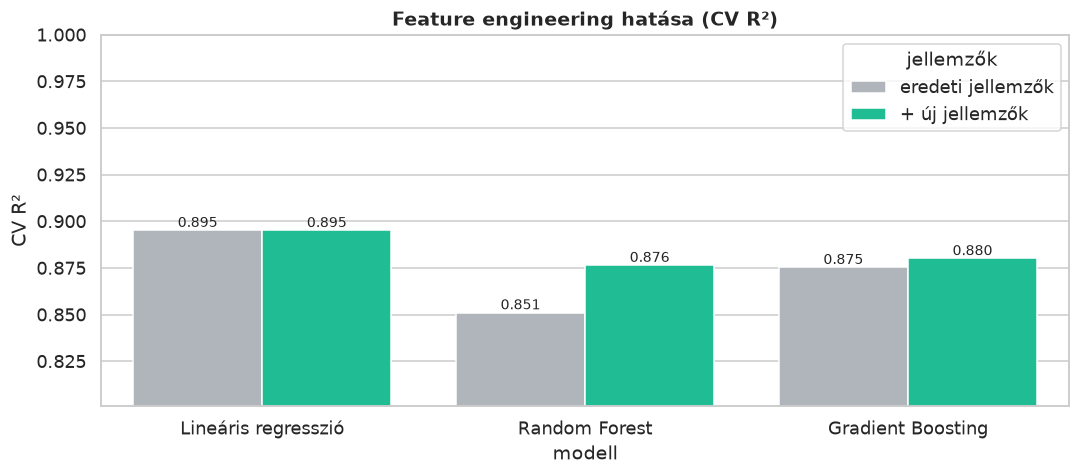

In [30]:
eredeti_num = [c for c in num_cols if c not in uj]
osszevet = []
for nev in ["Lineáris regresszió", "Random Forest", "Gradient Boosting"]:
    for cimke, cols in [("eredeti jellemzők", eredeti_num), ("+ új jellemzők", num_cols)]:
        pipe = Pipeline([("pre", elofeldolgozo(cols)), ("model", reg_modellek[nev])])
        sc = cross_val_score(pipe, X_train, y_train, cv=kf, scoring="r2")
        osszevet.append({"modell": nev, "jellemzők": cimke, "CV R²": sc.mean()})
osszevet = pd.DataFrame(osszevet)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=osszevet, x="modell", y="CV R²", hue="jellemzők", palette=["#adb5bd", "#06d6a0"], ax=ax)
for c in ax.containers: ax.bar_label(c, fmt="%.3f", fontsize=9)
ax.set_ylim(osszevet["CV R²"].min() - 0.05, 1)
ax.set_title("Feature engineering hatása (CV R²)")
plt.tight_layout(); ment("19_feature_engineering_hatas"); plt.show()

**Értelmezés:** A lineáris regressziónál az új jellemzők semmit nem változtattak (0,895 → 0,895), mivel a lineáris modell
az eredeti változók kombinációit magától is meg tudja tanulni. A **Random Forestnél viszont érezhető a javulás (0,851 → 0,876)**,
mert egy fa a szorzatokat és arányokat (pl. `productive_hours`, `study_screen_ratio`) csak sok vágással tudná közelíteni.
A Gradient Boosting kicsit javult (0,875 → 0,880).

### 8.3 A legjobb modell részletes vizsgálata

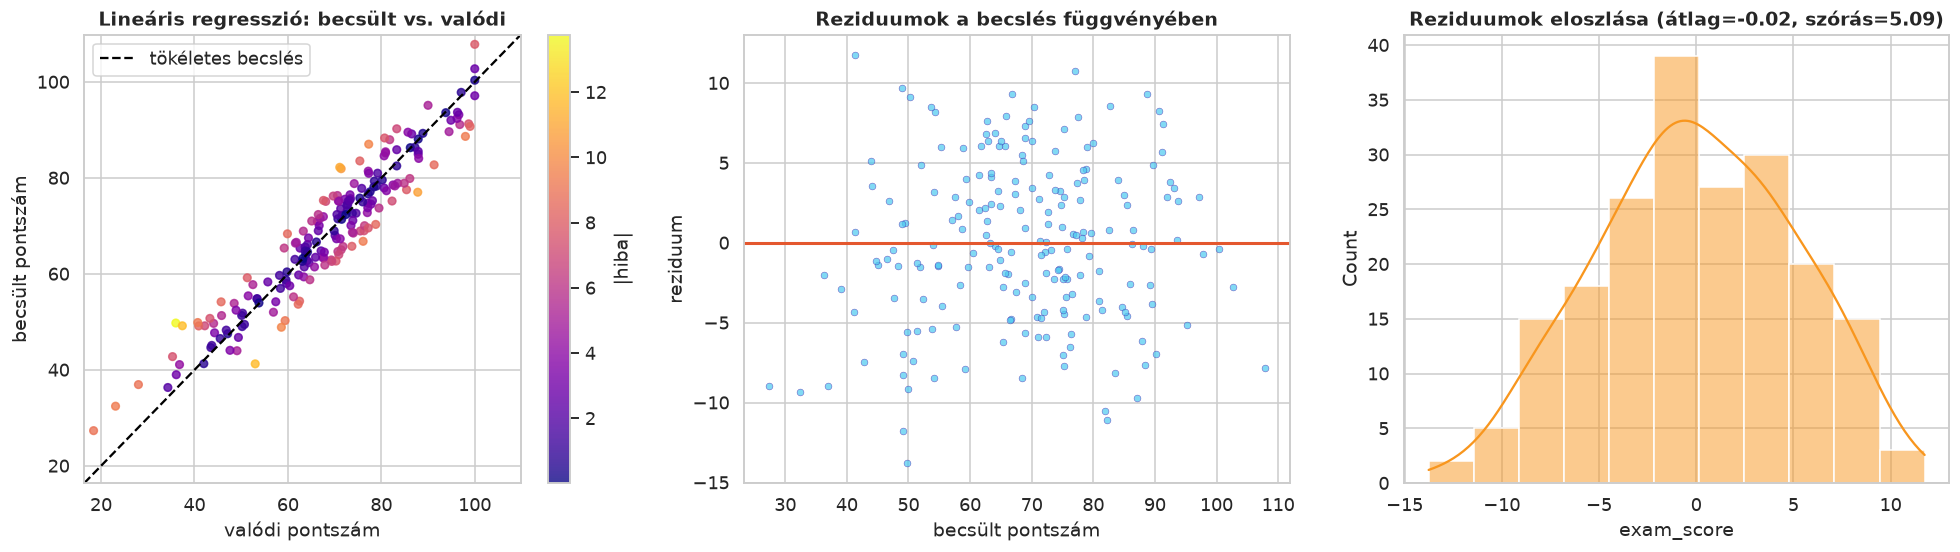

In [31]:
legjobb_nev = reg_df.index[0]
legjobb = reg_pipek[legjobb_nev]
pred = legjobb.predict(X_test)
rezid = y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
sc = axes[0].scatter(y_test, pred, c=np.abs(rezid), cmap="plasma", s=25, alpha=.8)
lim = [min(y_test.min(), pred.min()) - 2, max(y_test.max(), pred.max()) + 2]
axes[0].plot(lim, lim, "k--", lw=1.5, label="tökéletes becslés")
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("valódi pontszám"); axes[0].set_ylabel("becsült pontszám"); axes[0].legend()
axes[0].set_title(f"{legjobb_nev}: becsült vs. valódi")
plt.colorbar(sc, ax=axes[0], label="|hiba|")

axes[1].scatter(pred, rezid, color="#4cc9f0", alpha=.7, s=20, edgecolor="#3a0ca3", linewidth=.3)
axes[1].axhline(0, color="#e4572e", lw=2)
axes[1].set_xlabel("becsült pontszám"); axes[1].set_ylabel("reziduum")
axes[1].set_title("Reziduumok a becslés függvényében")

sns.histplot(rezid, kde=True, color="#f8961e", ax=axes[2])
axes[2].set_title(f"Reziduumok eloszlása (átlag={rezid.mean():.2f}, szórás={rezid.std():.2f})")
plt.tight_layout(); ment("20_legjobb_modell_reziduumok"); plt.show()

**Értelmezés:** A pontok szorosan az átló körül vannak. A reziduumok nagyjából normális eloszlásúak, 0 körül szimmetrikusak,
és nincs bennük erős mintázat, tehát a modell feltételezései nagyjából teljesülnek. A magas becsléseknél viszont
megjelenik a plafonhatás: 100 pontnál többet a valóságban nem lehet elérni, a lineáris modell viszont „túl tud lőni”.

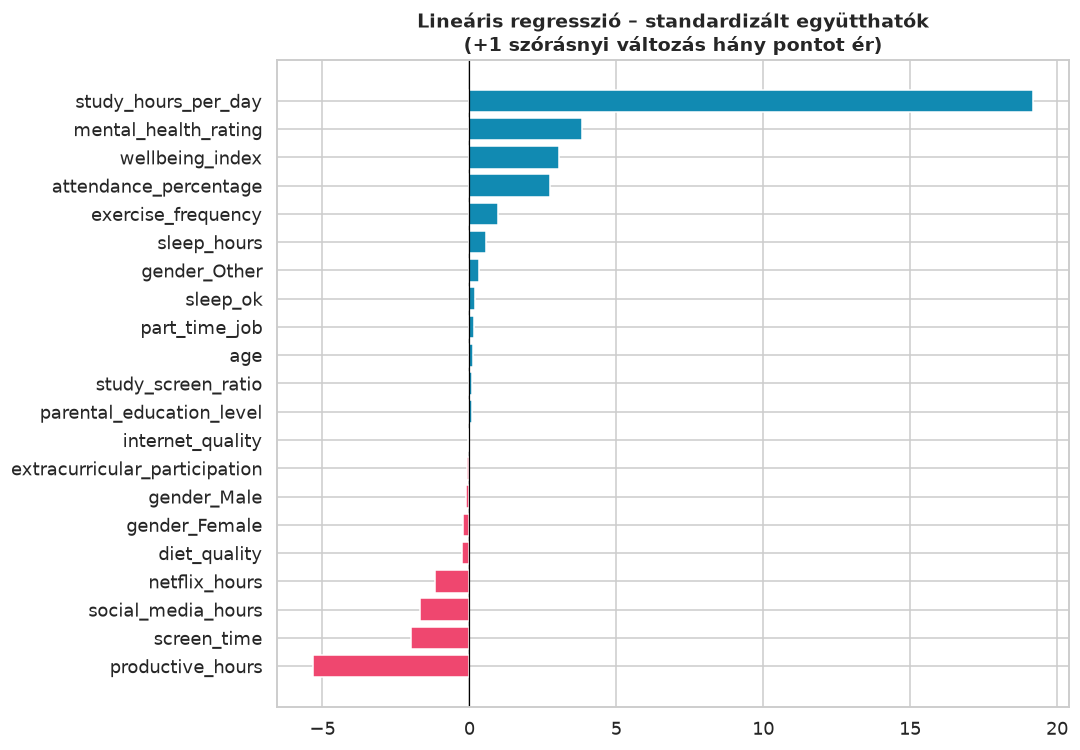

In [32]:
# lineáris modell együtthatói (standardizált jellemzőkön, tehát egymással összemérhetők)
lin = reg_pipek["Lineáris regresszió"]
nevek = lin.named_steps["pre"].get_feature_names_out()
nevek = [n.split("__", 1)[1] for n in nevek]
egyutt = pd.Series(lin.named_steps["model"].coef_, index=nevek).sort_values()

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(egyutt.index, egyutt.values, color=["#ef476f" if v < 0 else "#118ab2" for v in egyutt])
ax.axvline(0, color="black", lw=.8)
ax.set_title("Lineáris regresszió – standardizált együtthatók\n(+1 szórásnyi változás hány pontot ér)")
plt.tight_layout(); ment("21_linearis_egyutthatok"); plt.show()

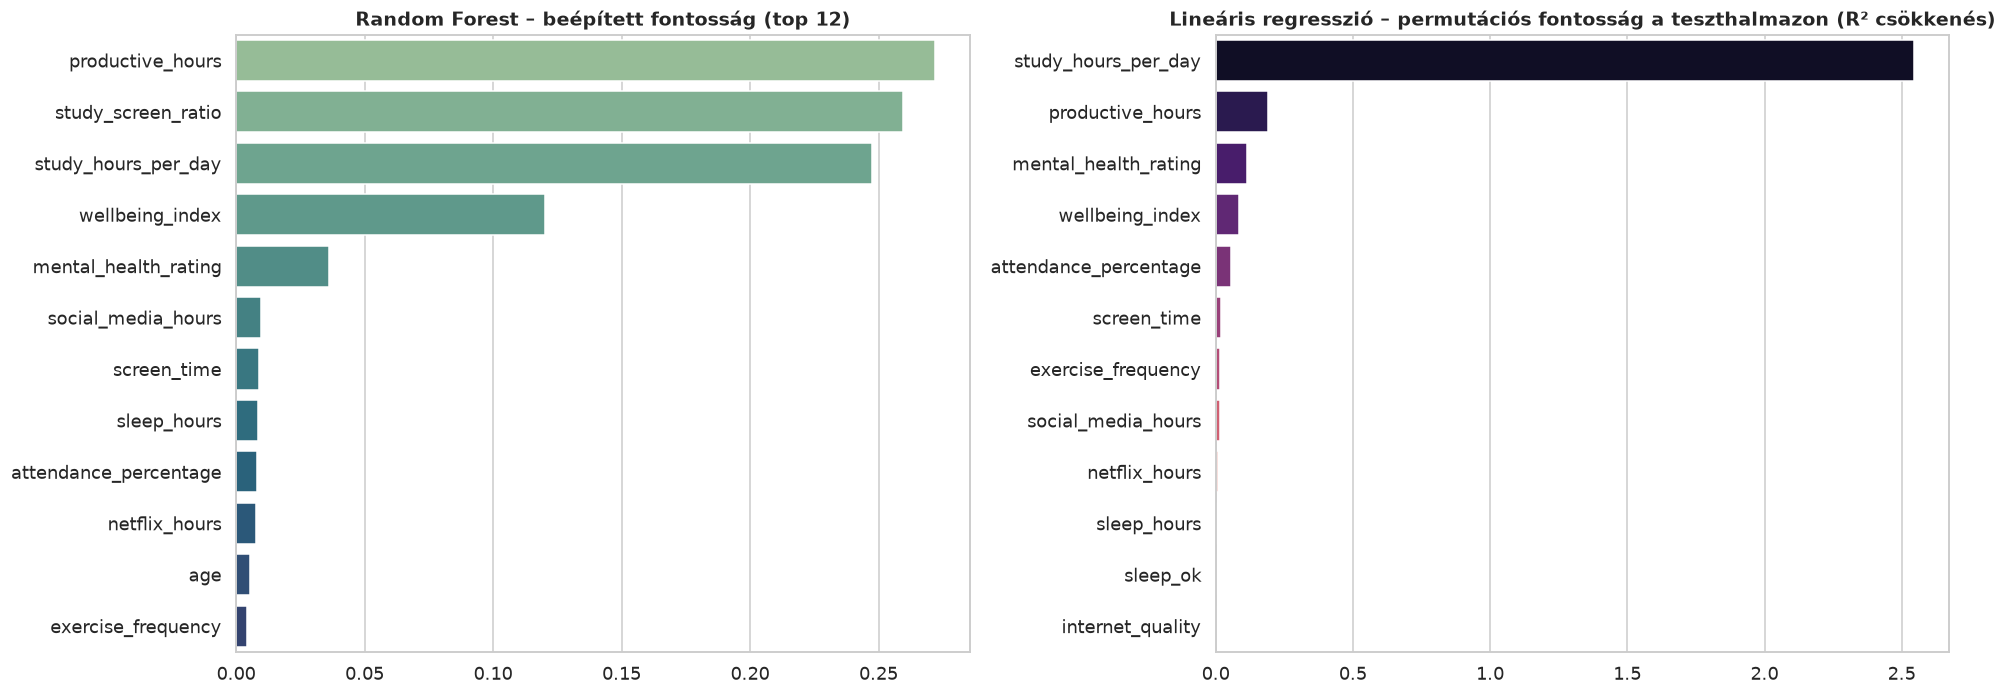

In [33]:
rf = reg_pipek["Random Forest"]
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=nevek).sort_values(ascending=False)

perm = permutation_importance(legjobb, X_test, y_test, n_repeats=15, random_state=RANDOM_STATE, scoring="r2")
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
sns.barplot(x=imp.values[:12], y=imp.index[:12], hue=imp.index[:12], palette="crest", legend=False, ax=axes[0])
axes[0].set_title("Random Forest – beépített fontosság (top 12)")
sns.barplot(x=perm_s.values[:12], y=perm_s.index[:12], hue=perm_s.index[:12], palette="magma", legend=False, ax=axes[1])
axes[1].set_title(f"{legjobb_nev} – permutációs fontosság a teszthalmazon (R² csökkenés)")
axes[0].set_ylabel(""); axes[1].set_ylabel("")
plt.tight_layout(); ment("22_jellemzo_fontossag"); plt.show()

**Értelmezés:** Mindhárom módszer (lineáris együtthatók, RF-fontosság, permutációs fontosság) ugyanazt mutatja:
**1. tanulási idő** (illetve az ebből képzett jellemzők), **2. mentális állapot** és a jóllét-index, majd jóval kisebb súllyal a jelenlét,
a képernyőidő, a sport és az alvás. A demográfiai változók (nem, életkor, szülői végzettség) gyakorlatilag nem számítanak.

Megjegyzés: a permutációs fontosságnál a `study_hours_per_day` értéke azért ilyen kiugró (az R² több mint 1-gyel csökken), mert
a lineáris modell erősen összefüggő jellemzőket kapott (`study_hours_per_day`, `productive_hours`, `study_screen_ratio`). Ha az egyiket
összekeverjük, a többi már nem tudja „kiegyensúlyozni”. Ez a multikollinearitás egyik jellegzetes hatása.

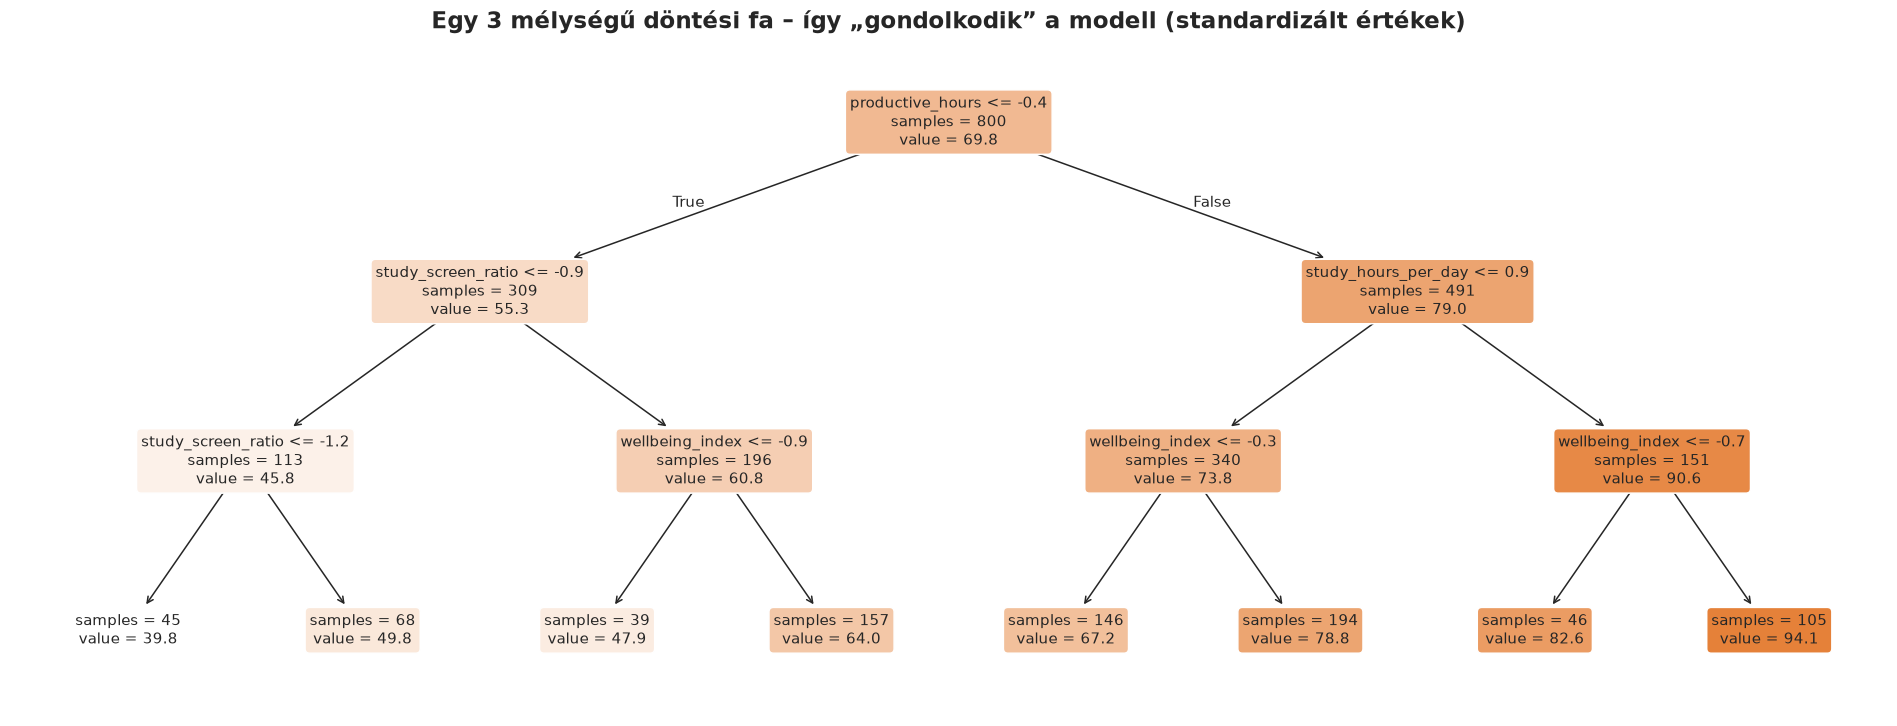

In [34]:
fa = Pipeline([("pre", elofeldolgozo(num_cols)), ("model", DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE))])
fa.fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(fa.named_steps["model"], feature_names=nevek, filled=True, rounded=True, fontsize=10, ax=ax, impurity=False, precision=1)
ax.set_title("Egy 3 mélységű döntési fa – így „gondolkodik” a modell (standardizált értékek)", fontsize=15)
ment("23_dontesi_fa"); plt.show()

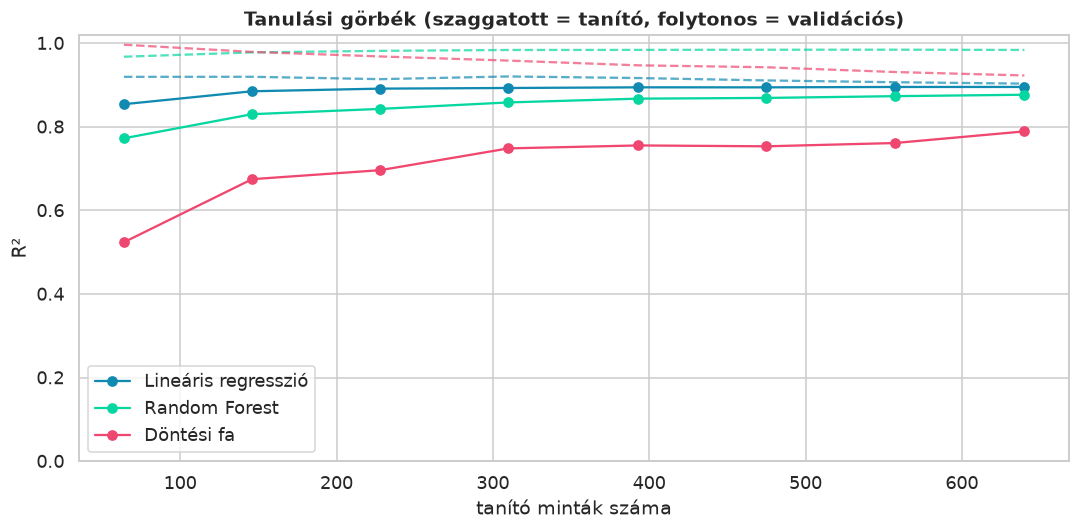

In [35]:
fig, ax = plt.subplots(figsize=(10, 5))
for nev, szin in [("Lineáris regresszió", "#118ab2"), ("Random Forest", "#06d6a0"), ("Döntési fa", "#ef476f")]:
    meret, tr, val = learning_curve(reg_pipek[nev], X_train, y_train, cv=kf, scoring="r2",
                                    train_sizes=np.linspace(.1, 1, 8))
    ax.plot(meret, tr.mean(1), "--", color=szin, alpha=.7)
    ax.plot(meret, val.mean(1), "o-", color=szin, label=nev)
ax.set_xlabel("tanító minták száma"); ax.set_ylabel("R²")
ax.set_title("Tanulási görbék (szaggatott = tanító, folytonos = validációs)")
ax.legend(); ax.set_ylim(0, 1.02)
plt.tight_layout(); ment("24_tanulasi_gorbek"); plt.show()

**Értelmezés:** A Random Forest tanító R²-e majdnem 1, a validációs viszont alacsonyabb. Ez **túltanulásra** utal. A lineáris
regressziónál a két görbe közel van egymáshoz, tehát jól általánosít. A döntési fa mindkét görbén gyengébb.

## 9. Osztályozási modellek – eléri-e a diák a 70 pontot?

A gyakorlatban sokszor nem a pontos pontszám érdekes, hanem az, hogy **ki van veszélyben**. Ezért a pontszámból bináris
célváltozót készítek: `sikeres = 1`, ha a pontszám ≥ 70.

Modellek: baseline (leggyakoribb osztály), logisztikus regresszió, KNN, döntési fa, Random Forest, Gradient Boosting és SVM.
A felosztás **rétegzett** (stratified), hogy mindkét halmazban azonos legyen az osztályarány.

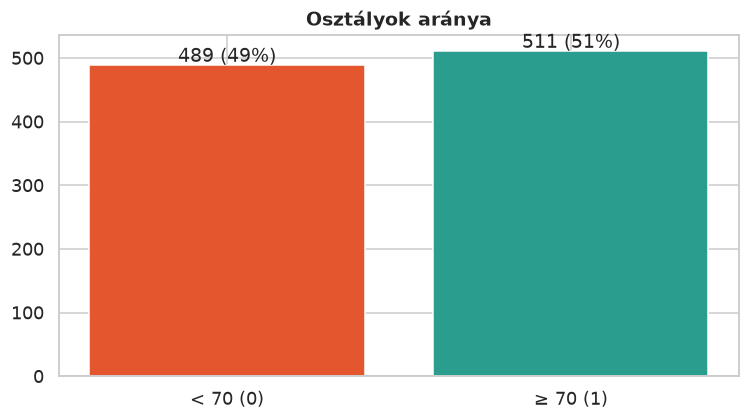

In [36]:
KUSZOB = 70
y_bin = (y >= KUSZOB).astype(int)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, y_bin, test_size=0.2, random_state=RANDOM_STATE, stratify=y_bin)

fig, ax = plt.subplots(figsize=(7, 4))
aranyok = y_bin.value_counts().sort_index()
ax.bar(["< 70 (0)", "≥ 70 (1)"], aranyok.values, color=["#e4572e", "#2a9d8f"])
for i, v in enumerate(aranyok.values): ax.text(i, v + 5, f"{v} ({v / len(y_bin):.0%})", ha="center")
ax.set_title("Osztályok aránya")
plt.tight_layout(); ment("25_osztaly_arany"); plt.show()

In [37]:
osz_modellek = {
    "Baseline (leggyakoribb)": DummyClassifier(strategy="most_frequent"),
    "Logisztikus regresszió": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "Döntési fa": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
}
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)

osz_eredmeny, osz_pipek = [], {}
for nev, modell in osz_modellek.items():
    pipe = Pipeline([("pre", elofeldolgozo(num_cols)), ("model", modell)])
    cv_f1 = cross_val_score(pipe, Xc_train, yc_train, cv=skf, scoring="f1")
    pipe.fit(Xc_train, yc_train)
    p = pipe.predict(Xc_test); proba = pipe.predict_proba(Xc_test)[:, 1]
    osz_pipek[nev] = pipe
    osz_eredmeny.append({"modell": nev, "CV F1": cv_f1.mean(),
                         "accuracy": accuracy_score(yc_test, p), "precision": precision_score(yc_test, p, zero_division=0),
                         "recall": recall_score(yc_test, p), "F1": f1_score(yc_test, p), "ROC AUC": roc_auc_score(yc_test, proba)})

osz_df = pd.DataFrame(osz_eredmeny).set_index("modell").sort_values("ROC AUC", ascending=False)
osz_df.style.background_gradient(cmap="PuBuGn").format("{:.3f}")

,CV F1,accuracy,precision,recall,F1,ROC AUC
modell,,,,,,
Logisztikus regresszió,0.903,0.890,0.900,0.882,0.891,0.957
Random Forest,0.891,0.880,0.898,0.863,0.880,0.948
Gradient Boosting,0.898,0.875,0.889,0.863,0.876,0.947
SVM,0.893,0.880,0.882,0.882,0.882,0.943
KNN,0.851,0.840,0.865,0.814,0.838,0.920
Döntési fa,0.875,0.835,0.897,0.765,0.825,0.904
Baseline (leggyakoribb),0.677,0.510,0.510,1.000,0.675,0.500


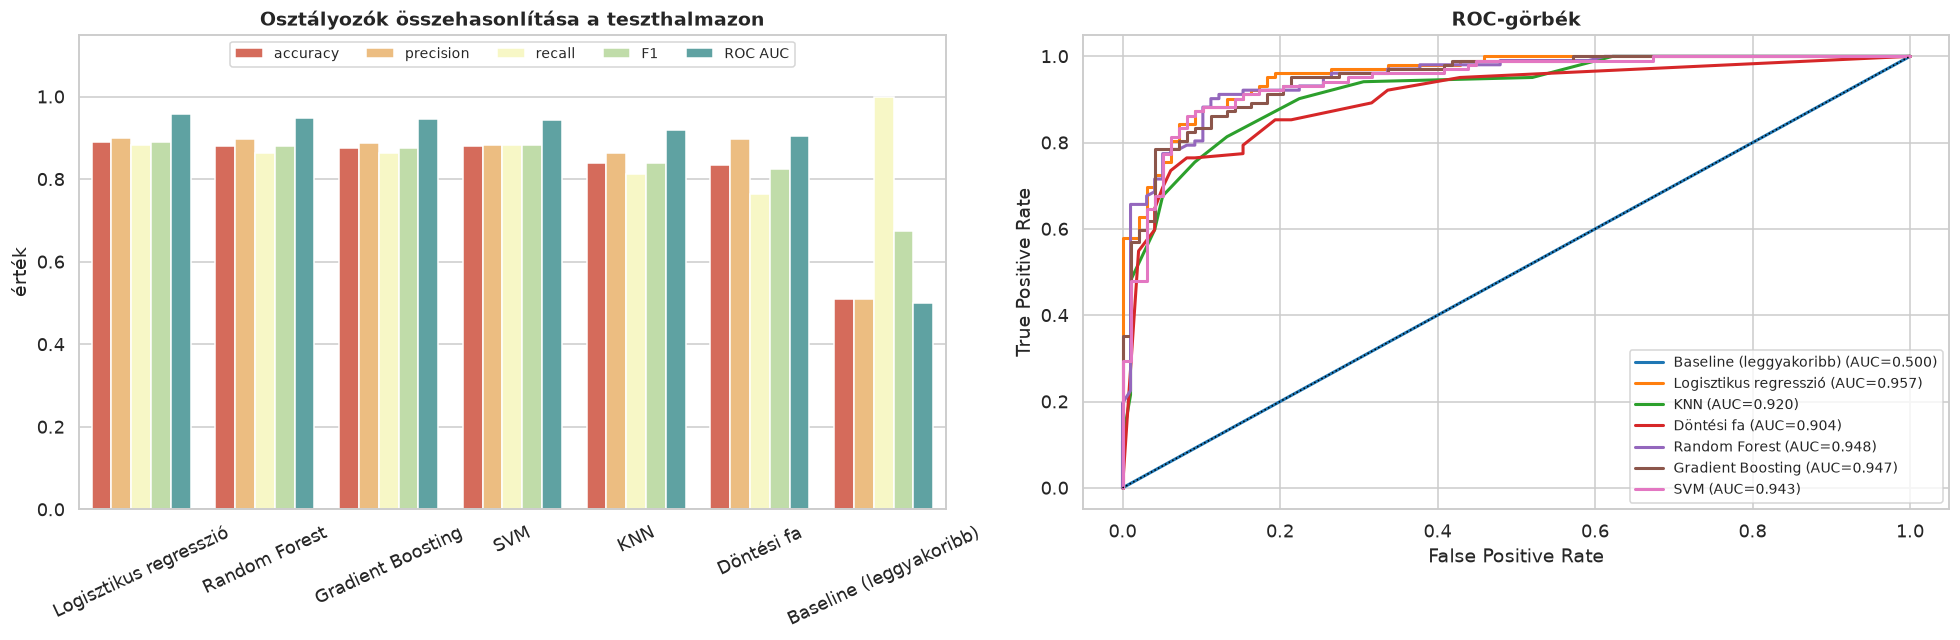

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
metr = osz_df[["accuracy", "precision", "recall", "F1", "ROC AUC"]].reset_index().melt(id_vars="modell", var_name="metrika", value_name="érték")
sns.barplot(data=metr, x="modell", y="érték", hue="metrika", palette="Spectral", ax=axes[0])
axes[0].set_title("Osztályozók összehasonlítása a teszthalmazon"); axes[0].tick_params(axis="x", rotation=25)
axes[0].set_ylim(0, 1.15); axes[0].legend(loc="upper center", ncol=5, fontsize=9); axes[0].set_xlabel("")

szinek = sns.color_palette("tab10", len(osz_pipek))
for (nev, pipe), szin in zip(osz_pipek.items(), szinek):
    proba = pipe.predict_proba(Xc_test)[:, 1]
    fpr, tpr, _ = roc_curve(yc_test, proba)
    axes[1].plot(fpr, tpr, color=szin, lw=2, label=f"{nev} (AUC={roc_auc_score(yc_test, proba):.3f})")
axes[1].plot([0, 1], [0, 1], "k:", lw=1)
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC-görbék"); axes[1].legend(loc="lower right", fontsize=9)
plt.tight_layout(); ment("26_osztalyozok_roc"); plt.show()

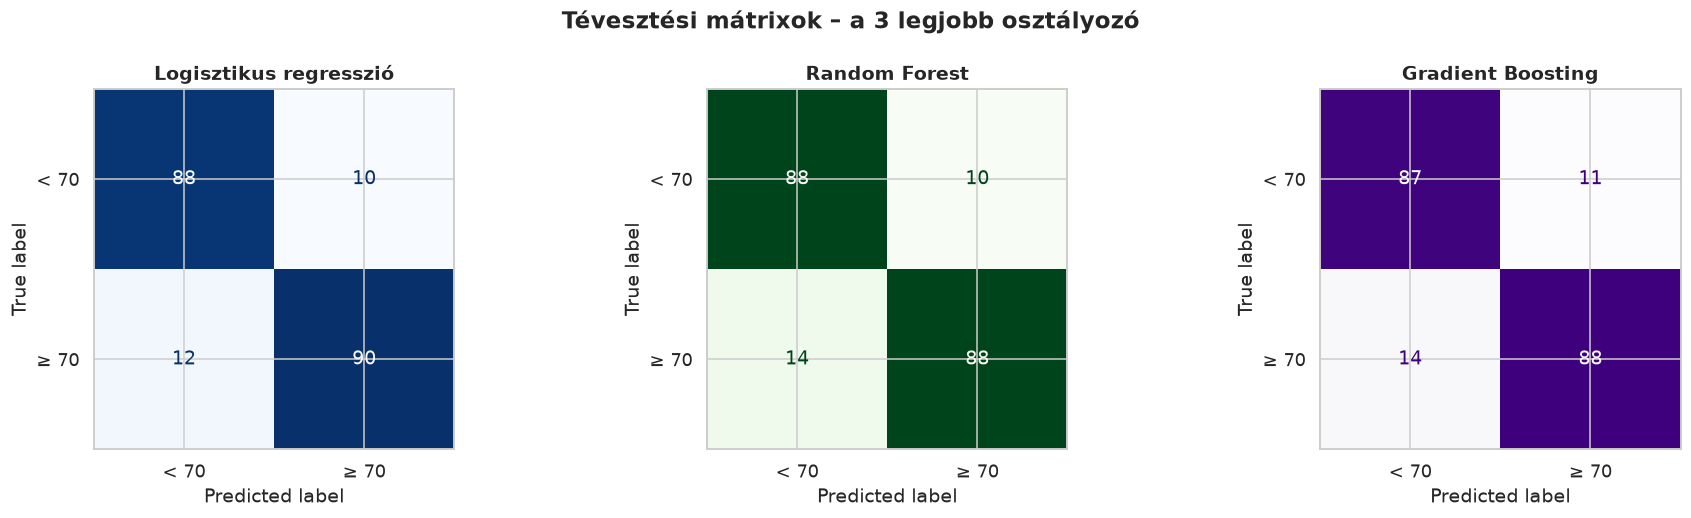

Legjobb osztályozó: Logisztikus regresszió

              precision    recall  f1-score   support

        < 70       0.88      0.90      0.89        98
        ≥ 70       0.90      0.88      0.89       102

    accuracy                           0.89       200
   macro avg       0.89      0.89      0.89       200
weighted avg       0.89      0.89      0.89       200



In [39]:
top3 = list(osz_df.index[:3])
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, nev, cmap in zip(axes, top3, ["Blues", "Greens", "Purples"]):
    ConfusionMatrixDisplay.from_estimator(osz_pipek[nev], Xc_test, yc_test, display_labels=["< 70", "≥ 70"],
                                          cmap=cmap, ax=ax, colorbar=False)
    ax.set_title(nev)
plt.suptitle("Tévesztési mátrixok – a 3 legjobb osztályozó", fontsize=15, fontweight="bold")
plt.tight_layout(); ment("27_tevesztesi_matrixok"); plt.show()

print(f"Legjobb osztályozó: {top3[0]}\n")
print(classification_report(yc_test, osz_pipek[top3[0]].predict(Xc_test), target_names=["< 70", "≥ 70"]))

**Értelmezés:** A baseline AUC-ja 0,5, ami a véletlen tippelésnek felel meg. Itt is a legegyszerűbb, **logisztikus regresszió** a legjobb
(AUC ≈ 0,96, accuracy ≈ 89%), de a Random Forest, a Gradient Boosting és az SVM is nagyon közel van hozzá. Ez összhangban van
a regressziós eredménnyel: a döntési határ nagyjából lineáris. A döntési fa és a KNN itt is gyengébb. A tévesztési mátrixokon
látszik, hogy a hibák főleg a 70 pont körüli „határesetekből” jönnek, ami természetes, mert ott kis különbség dönt.

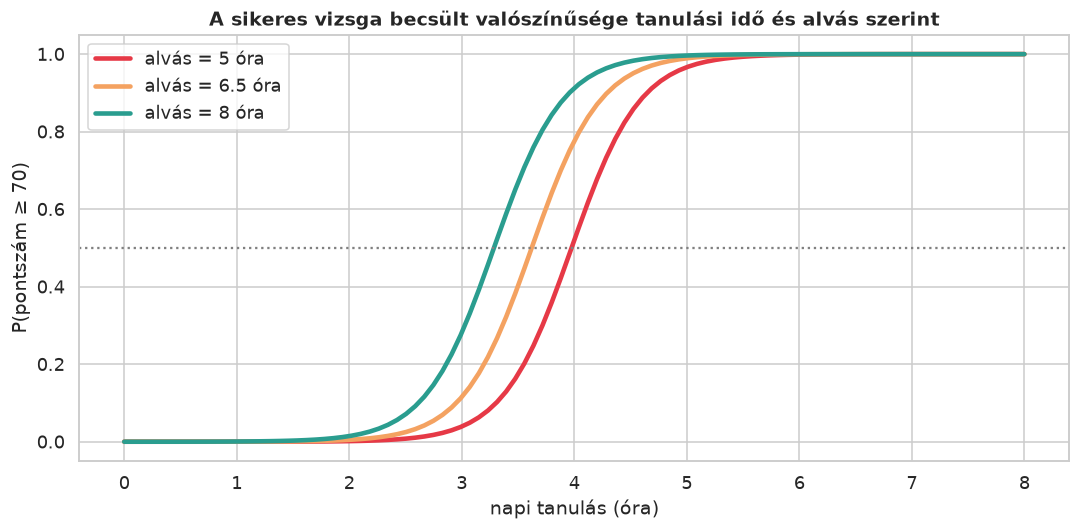

In [40]:
# hogyan függ a siker valószínűsége a tanulástól? (logisztikus regresszió, a többi változó átlagos/leggyakoribb értéken)
lr = osz_pipek["Logisztikus regresszió"]
alap = pd.DataFrame([X_train.median(numeric_only=True)])
for c in list(ORD_KAT) + NOM_KAT:
    alap[c] = X_train[c].mode()[0]
racs = pd.concat([alap] * 100, ignore_index=True)

fig, ax = plt.subplots(figsize=(10, 5))
for alvas, szin in [(5, "#e63946"), (6.5, "#f4a261"), (8, "#2a9d8f")]:
    r = racs.copy()
    r["study_hours_per_day"] = np.linspace(0, 8, 100)
    r["sleep_hours"] = alvas
    # a származtatott jellemzőket újra kell számolni, mert a tanulás és az alvás változott
    r["screen_time"] = r["social_media_hours"] + r["netflix_hours"]
    r["study_screen_ratio"] = r["study_hours_per_day"] / (r["screen_time"] + 1)
    r["productive_hours"] = r["study_hours_per_day"] * r["attendance_percentage"] / 100
    r["sleep_ok"] = int(7 <= alvas <= 9)
    z = lambda col: (r[col] - df[col].mean()) / df[col].std()
    r["wellbeing_index"] = (z("sleep_hours") + z("exercise_frequency") + z("mental_health_rating")) / 3
    ax.plot(r["study_hours_per_day"], lr.predict_proba(r[X_train.columns])[:, 1], lw=3, color=szin, label=f"alvás = {alvas} óra")
ax.axhline(.5, color="grey", ls=":")
ax.set_xlabel("napi tanulás (óra)"); ax.set_ylabel("P(pontszám ≥ 70)")
ax.set_title("A sikeres vizsga becsült valószínűsége tanulási idő és alvás szerint")
ax.legend()
plt.tight_layout(); ment("28_siker_valoszinuseg"); plt.show()

**Értelmezés:** Ez a görbe az egész projekt egyik leginkább „gyakorlati” eredménye. Egy átlagos diáknál kb. napi 3–4 óra tanulás
körül fordul át a siker esélye 50% fölé. A több alvás balra tolja a görbét: 8 óra alvással kb. 3,3 óra tanulás is elég
az 50%-hoz, 5 óra alvással viszont kb. 4 óra kell. Persze ez a modell becslése, nem ok-okozati bizonyíték.

## 10. Eredmények összegzése és következtetések

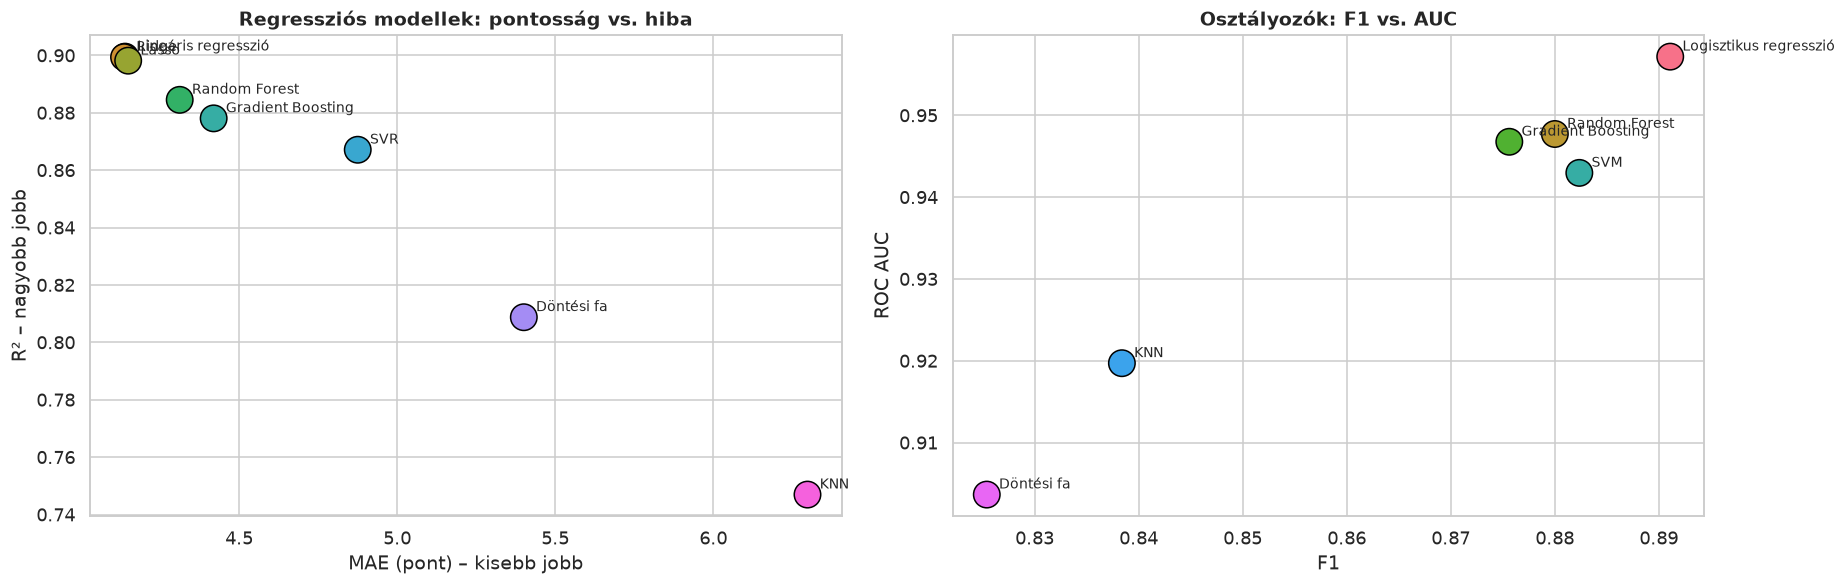

Legjobb regressziós modell: Lineáris regresszió | R² = 0.900, MAE = 4.14 pont
Legjobb osztályozó: Logisztikus regresszió | AUC = 0.957, F1 = 0.891


In [41]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
r = reg_df.drop(index="Baseline (átlag)")
axes[0].scatter(r["teszt MAE"], r["teszt R²"], s=300, c=sns.color_palette("husl", len(r)), edgecolor="black")
for nev, row in r.iterrows():
    axes[0].annotate(nev, (row["teszt MAE"], row["teszt R²"]), xytext=(8, 4), textcoords="offset points", fontsize=9)
axes[0].set_xlabel("MAE (pont) – kisebb jobb"); axes[0].set_ylabel("R² – nagyobb jobb")
axes[0].set_title("Regressziós modellek: pontosság vs. hiba")

o = osz_df.drop(index="Baseline (leggyakoribb)")
axes[1].scatter(o["F1"], o["ROC AUC"], s=300, c=sns.color_palette("husl", len(o)), edgecolor="black")
for nev, row in o.iterrows():
    axes[1].annotate(nev, (row["F1"], row["ROC AUC"]), xytext=(8, 4), textcoords="offset points", fontsize=9)
axes[1].set_xlabel("F1"); axes[1].set_ylabel("ROC AUC")
axes[1].set_title("Osztályozók: F1 vs. AUC")
plt.tight_layout(); ment("29_osszegzes"); plt.show()

print("Legjobb regressziós modell:", reg_df.index[0],
      f"| R² = {reg_df.iloc[0]['teszt R²']:.3f}, MAE = {reg_df.iloc[0]['teszt MAE']:.2f} pont")
print("Legjobb osztályozó:", osz_df.index[0],
      f"| AUC = {osz_df.iloc[0]['ROC AUC']:.3f}, F1 = {osz_df.iloc[0]['F1']:.3f}")

### Összefoglalás

**Az adatról**
- Kb. 1000 diák, 15 változó. Csak a szülői végzettség hiányzott (~9%), ezt külön „Unknown” kategóriaként kezeltem.
  Logikailag lehetetlen értéket és duplikátumot nem találtam.

**A hipotézisekről**
- A **tanulási idő** messze a legfontosabb tényező, utána a **mentális állapot** jön.
- Az alvás, a sport és az óralátogatás pozitívan, a közösségi média és a Netflix negatívan függ össze a pontszámmal, de ezek hatása kisebb.
- A **demográfiai jellemzők** (nem, kor, szülői végzettség) nem befolyásolják érdemben az eredményt.

**A modellekről**
- A legjobb eredményt az **egyszerű lineáris modellek** adták (teszt R² ≈ 0,90, MAE ≈ 4,1 pont, a baseline 12,4 pontos hibájához képest). A Random Forest és a
  Gradient Boosting nem javított rajtuk, a RF ráadásul túltanult. Ez is mutatja, hogy **nem a legbonyolultabb módszer a legjobb**,
  ha az adat szerkezete egyszerű.
- Osztályozásnál a logisztikus regresszió lett a legjobb (AUC ≈ 0,96, kb. 89%-os pontosság). Jó, könnyen értelmezhető modell a „veszélyeztetett” diákok kiszűrésére.
- Az új jellemzők a lineáris modellen nem, a Random Foreston viszont érezhetően javítottak.
- A részmunka, az étkezés és a nem hatása nem volt szignifikáns.

**Korlátok**
- Az adathalmaz a Kaggle leírása szerint **szimulált**, ezért a valóságban a kapcsolatok valószínűleg zajosabbak és gyengébbek.
- Önbevallásos adatok (pl. mentális állapot, tanulási idő) torzulhatnak.
- Az összefüggések **korrelációk**, ok-okozati következtetést nem lehet levonni belőlük.

**Továbblépési lehetőségek**
- Valós (nem szimulált) adatokon megismételni az elemzést.
- Kölcsönhatások vizsgálata (pl. tanulás × alvás), illetve polinomiális tagok a lineáris modellben.
- A 100 pontos plafon kezelése (pl. cenzorált regresszió).